# 09 · Latent diffusion, and using Stable Diffusion with 🤗 diffusers

Large text-to-image systems such as Stable Diffusion are built from the parts of notebooks 01–08 plus one new idea:
**run the diffusion model in the latent space of a pretrained autoencoder**. In **Part A** we build a tiny latent
diffusion model end to end on MNIST (autoencoder, latent scale factor, class-conditional latent U-Net, classifier-free
guidance, decoder). It runs on a laptop CPU. In **Part B** we take real Stable Diffusion apart with the `diffusers`
library and map every knob to an earlier notebook. Part B needs a GPU and access to the Hugging Face Hub.
Section 7 of Part A is the bridge between the two: it drives our small model with `diffusers`' samplers. It needs only
`pip install diffusers`, runs on a CPU and downloads nothing.

**You will learn:**
- why diffusing in a learned latent space is so much cheaper ("perceptual" vs "semantic" compression), and what it costs;
- to build and train a **KL-regularised autoencoder**, and why the **latent scale factor** (Stable Diffusion's `0.18215`)
  is really part of the noise schedule;
- to train a class-conditional **latent diffusion model** and assemble a miniature Stable Diffusion pipeline:
  condition → random latents → guided denoising → decode;
- **img2img (SDEdit)** in latent space and its `strength` knob;
- the `diffusers` **scheduler API** (`set_timesteps`, `scale_model_input`, `step`), checked against our own DDIM, plus
  two gotchas: timestep spacing and `clip_sample`;
- the anatomy of Stable Diffusion (CLIP text encoder, `UNet2DConditionModel`, `AutoencoderKL`, scheduler), a
  **hand-written sampling loop**, and the practical knobs: samplers and step counts, guidance scale, negative prompts,
  img2img, inpainting, one-step distilled models, memory and speed.

**Prerequisites:** 01 (forward process, SNR), 02 (DDPM), 03 (Tweedie), 04 (DDIM), 05 (U-Net, EMA, training recipe),
06 (classifier-free guidance, negative prompts), 07 (SDEdit, inpainting). Section 8 refers to 08 (flow matching).

**Runtime:** Part A: about 10–15 min on a 4-core CPU, most of it two short training runs (the autoencoder and the
latent diffusion model), and longer if other jobs share the CPU; about 2–3 min on a GPU. A full run saves both
trained models to `checkpoints/09_latent_mnist.pt`, and later runs reload them, so a restart costs only a few
minutes. Part B (optional) needs a CUDA GPU with ≥ 6 GB of memory (or an Apple-silicon Mac) and a one-off download
of several GB of weights per model; after that, a few minutes.

In [1]:
import copy
import contextlib
import importlib.util
import math
import time

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

import dmtools as dm

device = dm.get_device(verbose=True)
FAST = dm.fast_mode()  # automated smoke-test switch, leave as is
dm.seed_everything(0)
plt.rcParams.update({"figure.dpi": 100, "font.size": 9, "axes.titlesize": 10,
                     "axes.labelsize": 9, "legend.fontsize": 8})

# bfloat16 autocast for *training*: ~2x faster on CUDA GPUs and on recent x86 CPUs (AVX-512/AMX), as in notebook 05.
# Off on Apple MPS. If training is *slower* with it on your CPU, set USE_AMP = False. Sampling always runs in float32.
USE_AMP = device.type == "cpu" or (device.type == "cuda" and torch.cuda.is_bf16_supported())


def autocast():
    """Mixed-precision context for training forward passes (a no-op when USE_AMP is False)."""
    return torch.autocast(device.type, dtype=torch.bfloat16) if USE_AMP else contextlib.nullcontext()


Z_CH, LAT = 4, 7                                  # latent shape (4, 7, 7), like SD's 4 latent channels
AE_STEPS = 40 if FAST else 1500                   # autoencoder training steps (batch 128)
LDM_STEPS = 40 if FAST else 3000                  # latent diffusion training steps (batch 128)
N_EVAL = 20 if FAST else 300                      # generated samples per guidance scale for the classifier check
RETRAIN = False                                   # True: ignore the models cached by an earlier full run, train again
C_PIX, C_LAT, C_REAL = "tab:blue", "tab:orange", "0.35"   # colours used throughout
print(f"FAST={FAST}  USE_AMP={USE_AMP}  AE_STEPS={AE_STEPS}  LDM_STEPS={LDM_STEPS}")

# Optional packages. §7 needs only diffusers (CPU, no download); Part B also needs transformers (CLIP) and a GPU.
HAVE_DIFFUSERS = importlib.util.find_spec("diffusers") is not None
HAVE_TRANSFORMERS = importlib.util.find_spec("transformers") is not None
if not HAVE_DIFFUSERS:
    print("diffusers is not installed: §7 will be skipped. To run it: pip install diffusers")

Using device: cpu
FAST=False  USE_AMP=True  AE_STEPS=1500  LDM_STEPS=3000


# Part A · A tiny latent diffusion model, end to end

## 1 · Why diffuse in a latent space?

A pixel-space diffusion model (notebook 05) runs its whole U-Net over every pixel, at every one of its sampling steps.
For a 512×512 RGB image that is 786 432 numbers per network call, and the cost of a convolution grows with the number
of spatial positions. Yet most of those numbers describe detail we barely perceive: the exact grain of a texture,
sensor noise, the precise anti-aliasing of an edge. Notebook 05 (§6) showed that sampling is **coarse-to-fine**: the
late, low-noise steps paint in exactly this detail, and the training loss spends network capacity on it like
on everything else.

Rombach et al. (2022) split the job in two:

1. **Perceptual compression.** An autoencoder $(E, D)$ maps an image $x$ to a smaller but still *spatial* latent
   $z=E(x)$ and back, $D(z)\approx x$, throwing away imperceptible detail. It is trained once and then frozen.
2. **Semantic compression.** A diffusion model learns the distribution of the latents, $p(z)$ or $p(z\mid\text{text})$.
   To sample, draw $z\sim p_\theta(z)$ with any sampler from notebooks 02–04 and decode, $x=D(z)$.

Nothing in notebooks 01–08 changes: the diffusion model simply sees a different dataset, $z$ instead of $x$. And
because the latent is still a 2-D grid, a convolutional U-Net still works, on a much smaller grid.

| | data | latent | numbers per image | spatial positions for the U-Net |
|---|---|---|---|---|
| Stable Diffusion 1.x | 3×512×512 | 4×64×64 (downsampling factor $f=8$) | 48× fewer | 64× fewer |
| this notebook (MNIST) | 1×28×28 | 4×7×7 ($f=4$) | 4× fewer | 16× fewer |

**How much of an image is "detail"?** A quick *linear* experiment: principal component analysis of MNIST. If a few
directions carry most of the variance, and the digit is already recognisable from them, then most of the 784 pixel
values are refinements that a decoder could fill in.

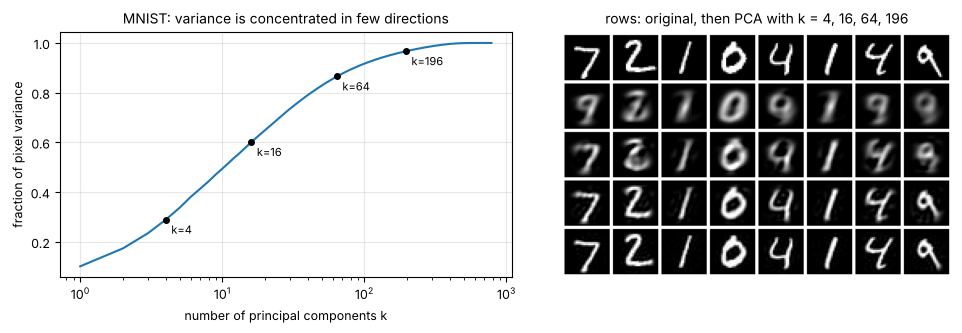

k =   4:  28.9% of the variance, test MSE per pixel 0.1889
k =  16:  60.1% of the variance, test MSE per pixel 0.1101
k =  64:  86.5% of the variance, test MSE per pixel 0.0376
k = 196:  96.7% of the variance, test MSE per pixel 0.0093


In [2]:
x_train, y_train = dm.load_mnist(train=True)
x_test, y_test = dm.load_mnist(train=False)

X = x_train[:10000].flatten(1).double()
pca_mean = X.mean(0)
_, S, Vh = torch.linalg.svd(X - pca_mean, full_matrices=False)    # rows of Vh = principal directions
explained = (S ** 2).cumsum(0) / (S ** 2).sum()


def pca_reconstruct(x, k):
    """Project images onto the top-k principal components and map back to pixels."""
    xc = x.flatten(1).double() - pca_mean
    return (pca_mean + xc @ Vh[:k].T @ Vh[:k]).float().view_as(x)


KS = [4, 16, 64, 196]
x_show = x_test[:8]
pca_mse = {k: F.mse_loss(pca_reconstruct(x_test[:2000], k), x_test[:2000]).item() for k in KS}

fig = plt.figure(figsize=(10, 3.4))
ax = fig.add_subplot(1, 2, 1)
ax.plot(np.arange(1, len(explained) + 1), explained.numpy(), color=C_PIX)
for k in KS:
    ax.plot(k, explained[k - 1].item(), "o", color="k", ms=4)
    ax.annotate(f"k={k}", (k, explained[k - 1].item()), textcoords="offset points", xytext=(4, -10), fontsize=8)
ax.set(xscale="log", xlabel="number of principal components k", ylabel="fraction of pixel variance",
       title="MNIST: variance is concentrated in few directions")
ax.grid(alpha=0.3)
ax = fig.add_subplot(1, 2, 2)
rows = [x_show] + [pca_reconstruct(x_show, k) for k in KS]
dm.show_images(torch.cat(rows), nrow=8, ax=ax, title="rows: original, then PCA with k = " + ", ".join(map(str, KS)))
plt.tight_layout()
plt.show()
for k in KS:
    print(f"k = {k:3d}: {100 * explained[k - 1]:5.1f}% of the variance, test MSE per pixel {pca_mse[k]:.4f}")

The digit's identity is readable from a few dozen of the 784 dimensions; the remaining directions mostly sharpen and
thicken strokes. An autoencoder does the same compression *nonlinearly*, can be trained to keep what is
perceptually important rather than what has high variance, and keeps a 2-D layout so that the denoiser can still be
a convolutional U-Net.

## 2 · Perceptual compression: a small KL-regularised autoencoder

### 2.1 The objective

The encoder outputs a diagonal Gaussian $q_\phi(z\mid x)=\mathcal N\big(\mu_\phi(x),\operatorname{diag}\sigma^2_\phi(x)\big)$
and the decoder a reconstruction $D_\theta(z)$. We minimise
$$\mathcal L(\phi,\theta)=\mathbb E_{x}\Big[\,\mathbb E_{z\sim q_\phi(z\mid x)}\,\ell\big(x, D_\theta(z)\big)\;+\;\beta\,
\mathrm{KL}\big(q_\phi(z\mid x)\,\big\|\,\mathcal N(0,I)\big)\Big].$$
With a Gaussian likelihood and $\beta=1$ this is the negative ELBO of a VAE (Kingma & Welling 2014). The KL term has a
closed form. For one coordinate with $q=\mathcal N(\mu,\sigma^2)$ and $p=\mathcal N(0,1)$,
$$\mathrm{KL}(q\|p)=\mathbb E_q\big[\log q(z)-\log p(z)\big]
=\mathbb E_q\Big[-\tfrac12\log\sigma^2-\tfrac{(z-\mu)^2}{2\sigma^2}+\tfrac{z^2}{2}\Big]
=\tfrac12\big(\mu^2+\sigma^2-1-\log\sigma^2\big),$$
using $\mathbb E_q(z-\mu)^2=\sigma^2$ and $\mathbb E_q z^2=\mu^2+\sigma^2$ (the $\log 2\pi$ terms cancel). The KL of the
whole latent is the sum over its independent coordinates. Gradients flow through the sampling step via the
**reparameterisation** $z=\mu+\sigma\odot\varepsilon$, $\varepsilon\sim\mathcal N(0,I)$.

**Why only a *light* KL?** In a VAE the prior $\mathcal N(0,I)$ *is* the generative model, so $\beta$ must be large
enough to make the aggregate posterior match it, and that costs blurry reconstructions. Here the prior over latents
will be learned by the diffusion model, so the autoencoder only has to (i) reconstruct faithfully, (ii) keep the
latents at a bounded scale (an unregularised encoder can make them arbitrarily large, tiny or anisotropic), and
(iii) be **robust to small latent errors**. The injected noise $\sigma$ teaches the decoder that nearby latents decode
to nearby images, and the diffusion model *will* make small errors. Stable Diffusion's autoencoder (the "kl-f8"
model of Rombach et al.) uses $\beta=10^{-6}$, with an L1 + perceptual (LPIPS) reconstruction loss plus a patch-based
adversarial loss, as in VQGAN (Esser et al. 2021). The last two are what make reconstructions of natural images
sharp. For MNIST a plain L1 loss is enough.

### 2.2 Implementation

Two stride-2 convolutions take 28×28 to 7×7 ($f=4$). The encoder's last layer outputs $2\times$`Z_CH` channels: the
mean and the log-variance.

In [3]:
class Encoder(nn.Module):
    """x (B,1,28,28) -> mean and log-variance of q(z|x), each (B, z_ch, 7, 7)."""

    def __init__(self, z_ch=Z_CH, ch=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, ch, 3, padding=1), nn.SiLU(),                        # 28x28
            nn.Conv2d(ch, 2 * ch, 4, stride=2, padding=1), nn.SiLU(),         # 14x14
            nn.Conv2d(2 * ch, 2 * ch, 4, stride=2, padding=1), nn.SiLU(),     # 7x7
            nn.Conv2d(2 * ch, 2 * ch, 3, padding=1), nn.SiLU(),
            nn.Conv2d(2 * ch, 2 * z_ch, 3, padding=1))

    def forward(self, x):
        mean, logvar = self.net(x).chunk(2, dim=1)
        # the same clamp as diffusers' DiagonalGaussianDistribution: exp(logvar) can never overflow
        return mean, logvar.clamp(-30.0, 20.0)


class Decoder(nn.Module):
    """z (B, z_ch, 7, 7) -> image (B,1,28,28) (unbounded; clamp to [-1, 1] for display)."""

    def __init__(self, z_ch=Z_CH, ch=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(z_ch, 2 * ch, 3, padding=1), nn.SiLU(),
            nn.Conv2d(2 * ch, 2 * ch, 3, padding=1), nn.SiLU(),
            nn.ConvTranspose2d(2 * ch, 2 * ch, 4, stride=2, padding=1), nn.SiLU(),   # 14x14
            nn.ConvTranspose2d(2 * ch, ch, 4, stride=2, padding=1), nn.SiLU(),       # 28x28
            nn.Conv2d(ch, 1, 3, padding=1))

    def forward(self, z):
        return self.net(z)


def kl_to_standard_normal(mean, logvar):
    """KL( N(mean, exp(logvar)) || N(0, 1) ) for every latent coordinate (derived above)."""
    return 0.5 * (mean ** 2 + logvar.exp() - 1.0 - logvar)


# Check the closed form against torch.distributions on random inputs.
m_, lv_ = torch.randn(1000), torch.randn(1000)
kl_ref = torch.distributions.kl_divergence(torch.distributions.Normal(m_, (0.5 * lv_).exp()),
                                           torch.distributions.Normal(0.0, 1.0))
assert torch.allclose(kl_to_standard_normal(m_, lv_), kl_ref, atol=1e-5)
encoder, decoder = Encoder().to(device), Decoder().to(device)
print(f"KL formula matches torch.distributions.  encoder {dm.count_params(encoder):,} params, "
      f"decoder {dm.count_params(decoder):,} params")

KL formula matches torch.distributions.  encoder 140,296 params, decoder 137,985 params


The training loop is short. Practical details: AdamW with a one-cycle learning rate (short warm-up, then cosine
decay), which converges well in a short run; bfloat16 autocast for the network, but losses in float32; and a fixed
KL weight `BETA`. Both loss terms are averages (per pixel and per latent coordinate), so `BETA` is not directly
comparable with SD's $10^{-6}$, which multiplies *sums*.

In [4]:
BETA = 1e-4


def train_autoencoder(enc, dec, x, steps, beta=BETA, batch_size=128, lr=2e-3, log_every=500, seed=0):
    """Train (enc, dec) with L1 reconstruction + beta * KL. Returns per-step (reconstruction, KL) losses."""
    params = list(enc.parameters()) + list(dec.parameters())
    opt = torch.optim.AdamW(params, lr=lr)
    lr_sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps, pct_start=0.05)
    g = torch.Generator().manual_seed(seed)
    hist = []
    enc.train(), dec.train()
    for step in range(steps):
        x0 = x[torch.randint(0, len(x), (batch_size,), generator=g)].to(device)
        with autocast():
            mean, logvar = enc(x0)
            z = mean + (0.5 * logvar).exp() * torch.randn_like(mean)     # reparameterisation trick
            x_rec = dec(z)
        rec = F.l1_loss(x_rec.float(), x0)
        kl = kl_to_standard_normal(mean.float(), logvar.float()).mean()
        loss = rec + beta * kl
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        lr_sched.step()
        hist.append((rec.item(), kl.item()))
        if (step + 1) % log_every == 0 or step + 1 == steps:
            r, k = np.mean(hist[-log_every:], axis=0)
            print(f"step {step + 1:5d} | L1 {r:.4f} | KL per coordinate {k:.3f}")
    enc.eval(), dec.eval()
    return np.array(hist)


# A full run caches both trained models (this autoencoder and the latent diffusion model of §3) in one file, keyed on
# the settings above, so a kernel restart does not cost another ~10 CPU minutes. Change Z_CH, BETA or a step count and
# the key no longer matches, so both models are retrained. FAST smoke tests never read or write the cache.
CACHE_PATH = None if FAST else dm.CKPT_DIR / "09_latent_mnist.pt"
CACHE_KEY = dict(z_ch=Z_CH, beta=BETA, ae_steps=AE_STEPS, ldm_steps=LDM_STEPS)
cache = None
if CACHE_PATH is not None and CACHE_PATH.exists() and not RETRAIN:
    ck = torch.load(CACHE_PATH, map_location="cpu", weights_only=True)      # plain tensors and numbers only
    cache = ck if ck.get("key") == CACHE_KEY else None

if cache is not None:
    encoder.load_state_dict(cache["encoder"])
    decoder.load_state_dict(cache["decoder"])
    encoder.eval(), decoder.eval()
    print(f"loaded the autoencoder from {CACHE_PATH.relative_to(dm.ROOT)} (set RETRAIN = True to train it again)")
else:
    t0 = time.time()
    ae_hist = train_autoencoder(encoder, decoder, x_train, AE_STEPS, log_every=max(10, AE_STEPS // 4))
    print(f"autoencoder trained in {(time.time() - t0) / 60:.1f} min")

step   375 | L1 0.2687 | KL per coordinate 2.234


step   750 | L1 0.0490 | KL per coordinate 5.967


step  1125 | L1 0.0311 | KL per coordinate 5.648


step  1500 | L1 0.0285 | KL per coordinate 5.552
autoencoder trained in 14.6 min


Two helpers wrap the frozen autoencoder. `encode` returns the posterior *mean*: our posterior standard deviation is
small (printed below), so a sample would differ only slightly. Diffusers' `vae.encode(x).latent_dist` gives you
both, `.mean` and `.sample(generator)`. Is the autoencoder good enough? Three checks: the reconstruction error,
compared with PCA using the same number of dimensions (196); whether a digit classifier still recognises the
reconstructions; and a look at the reconstructions and at the latents themselves.

test MSE per pixel: autoencoder 0.0083  vs  PCA with 196 components 0.0093
classifier accuracy: originals 0.982, reconstructions 0.973
median posterior std sigma(x): 0.023


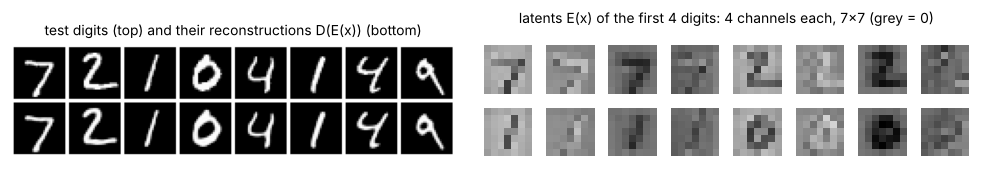

In [5]:
@torch.no_grad()
def encode(x, bs=1000):
    """Images in [-1, 1] -> posterior means (B, Z_CH, 7, 7) (unscaled), in batches, float32."""
    return torch.cat([encoder(x[i:i + bs].to(device))[0] for i in range(0, len(x), bs)])


@torch.no_grad()
def decode(z, bs=1000):
    """Latents (unscaled) -> images, in batches, float32."""
    return torch.cat([decoder(z[i:i + bs].to(device)) for i in range(0, len(z), bs)])


clf = dm.load_or_train_classifier(device)            # the small CNN of notebook 05 (~99% test accuracy)


@torch.no_grad()
def classify(x, bs=1000):
    """Predicted digit (argmax) and softmax probabilities of the notebook-05 classifier."""
    p = torch.cat([F.softmax(clf(x[i:i + bs].to(device).clamp(-1, 1)), 1) for i in range(0, len(x), bs)])
    return p.argmax(1).cpu(), p.cpu()


x_eval, y_eval = x_test[:2000], y_test[:2000]
with torch.no_grad():
    _, logvar_eval = encoder(x_eval.to(device))
x_rec = decode(encode(x_eval)).cpu()
ae_mse = F.mse_loss(x_rec, x_eval).item()
acc_orig = (classify(x_eval)[0] == y_eval).float().mean().item()
acc_rec = (classify(x_rec)[0] == y_eval).float().mean().item()
print(f"test MSE per pixel: autoencoder {ae_mse:.4f}  vs  PCA with 196 components {pca_mse[196]:.4f}")
print(f"classifier accuracy: originals {acc_orig:.3f}, reconstructions {acc_rec:.3f}")
print(f"median posterior std sigma(x): {(0.5 * logvar_eval).exp().median().item():.3f}")

z_show = encode(x_show).cpu()
fig, axes = plt.subplots(1, 2, figsize=(10, 2.6), gridspec_kw=dict(width_ratios=[1, 1.15]))
dm.show_images(torch.cat([x_show, decode(z_show).cpu()]), nrow=8, ax=axes[0],
               title="test digits (top) and their reconstructions D(E(x)) (bottom)")
# the Z_CH latent channels of the first 4 digits (two digits per row), normalised by the overall latent range
lat_imgs = z_show[:4].reshape(-1, 1, LAT, LAT)
dm.show_images(lat_imgs / z_show.abs().max(), nrow=2 * Z_CH, ax=axes[1],
               title=f"latents E(x) of the first 4 digits: {Z_CH} channels each, {LAT}x{LAT} (grey = 0)")
plt.tight_layout()
plt.show()

The reconstructions are close to the originals and the classifier still recognises them. That is the property that
matters: the autoencoder keeps the *semantics*. Measured by MSE, it is about as good as PCA with the same number of
dimensions; MNIST is easy, and PCA is the best *linear* code for MSE. The autoencoder's advantages lie elsewhere:
its latent is a spatial grid, so the denoiser can still be a convolutional U-Net, and on natural images it can be
trained with perceptual and adversarial losses to keep what matters to the eye rather than what has the most
variance. The latents are not images: each digit becomes four coarse 7×7
feature maps that still roughly follow the shape of the digit. That spatial correspondence is what lets
Stable Diffusion's latent U-Net use convolutions, and lets inpainting masks be downsampled into latent space.
Whatever the decoder cannot reproduce, the latent diffusion model cannot generate either: **the autoencoder's
reconstruction quality is a ceiling on sample quality** (equivalently, its reconstruction error is a floor on the
sample error).

### 2.3 The latent scale factor (Stable Diffusion's `0.18215`)

The forward process $z_t=\sqrt{\bar\alpha_t}\,z_0+\sqrt{1-\bar\alpha_t}\,\varepsilon$ was designed for data of roughly
unit variance. If the latents have standard deviation $s$, the signal-to-noise ratio at step $t$ is
$$\mathrm{SNR}_{\text{eff}}(t)=\frac{s^2\,\bar\alpha_t}{1-\bar\alpha_t},\qquad
\log\mathrm{SNR}_{\text{eff}}(t)=\log\mathrm{SNR}(t)+2\log s .$$
Scaling the data **shifts the whole log-SNR curve** (notebook 01 §4: the SNR curve is what really defines a
schedule). With $s\gg1$, every step is less noisy than intended: training effort goes to noise levels where the latent
is barely perturbed, and at $t=T-1$ the latent still carries signal, while sampling starts from pure
$\mathcal N(0,I)$. That is a train/test mismatch at the very first step. With $s\ll1$, the signal is destroyed
early and the interesting part of the schedule is crammed into a few small $t$.

The fix is one number. Compute the standard deviation of the training latents once and multiply by
$c=1/s$: train the diffusion model on $c\,E(x)$, and decode generated latents with $D(z/c)$. Stable Diffusion's
autoencoder produces latents with $s\approx5.5$, hence `vae.config.scaling_factor = 0.18215`. SDXL's autoencoder
uses `0.13025`. Flux also subtracts a mean, a `shift_factor` of `0.1159`, before scaling by `0.3611`.

**Gotchas:** forgetting the $1/c$ before decoding gives washed-out or garbled images (§7 shows it). Forgetting $c$
during training gives the SNR shift above. In neither case does anything crash.

raw latents: mean -0.386, std 2.180; per-channel std [1.837 1.178 1.889 1.31 ]
our scale factor c = 1/std = 0.4588   ->   scaled latents: std 1.000


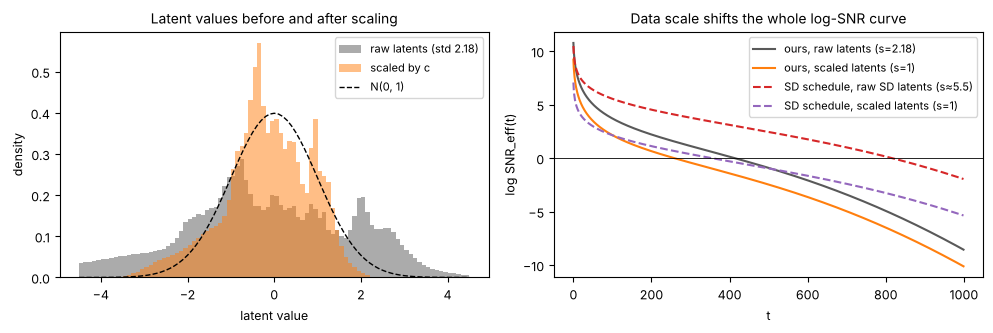

ours, raw latents (s=2.18)            : SNR at t=T-1 = 1.92e-04, correlation of z_T with z_0 = 0.014
ours, scaled latents (s=1)            : SNR at t=T-1 = 4.04e-05, correlation of z_T with z_0 = 0.006
SD schedule, raw SD latents (s≈5.5)   : SNR at t=T-1 = 1.42e-01, correlation of z_T with z_0 = 0.352
SD schedule, scaled latents (s=1)     : SNR at t=T-1 = 4.68e-03, correlation of z_T with z_0 = 0.068


In [6]:
z_raw = encode(x_train).cpu()                     # posterior means of all 60k training images
latent_std = z_raw.std().item()
SCALE = 1.0 / latent_std
z_train = z_raw * SCALE
print(f"raw latents: mean {z_raw.mean().item():+.3f}, std {latent_std:.3f}; per-channel std "
      f"{np.round(z_raw.std(dim=(0, 2, 3)).numpy(), 3)}")
print(f"our scale factor c = 1/std = {SCALE:.4f}   ->   scaled latents: std {z_train.std().item():.3f}")


def log_snr_eff(alpha_bars, s):
    """log SNR of x_t = sqrt(abar) * x0 + sqrt(1 - abar) * eps when x0 has standard deviation s."""
    ab = np.asarray(alpha_bars, dtype=np.float64)
    return np.log(s ** 2 * ab / (1 - ab))


schedule = dm.NoiseSchedule(1000, "linear", device=device)      # the schedule of notebooks 02-06
abar_ours = schedule.alpha_bars.cpu().double().numpy()        # .cpu() first: MPS has no float64
# Stable Diffusion's "scaled_linear" schedule: betas linear in sqrt-space between 0.00085 and 0.012
abar_sd = np.cumprod(1 - np.linspace(0.00085 ** 0.5, 0.012 ** 0.5, 1000) ** 2)
tt = np.arange(1000)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
bins = np.linspace(-4.5, 4.5, 91)
axes[0].hist(z_raw.flatten().numpy(), bins=bins, density=True, alpha=0.5, color=C_REAL, label=f"raw latents (std {latent_std:.2f})")
axes[0].hist(z_train.flatten().numpy(), bins=bins, density=True, alpha=0.5, color=C_LAT, label="scaled by c")
axes[0].plot(bins, np.exp(-bins ** 2 / 2) / np.sqrt(2 * np.pi), "k--", lw=1, label="N(0, 1)")
axes[0].set(xlabel="latent value", ylabel="density", title="Latent values before and after scaling")
axes[0].legend()
curves = [(abar_ours, latent_std, C_REAL, "-", f"ours, raw latents (s={latent_std:.2f})"),
          (abar_ours, 1.0, C_LAT, "-", "ours, scaled latents (s=1)"),
          (abar_sd, 5.5, "tab:red", "--", "SD schedule, raw SD latents (s≈5.5)"),
          (abar_sd, 1.0, "tab:purple", "--", "SD schedule, scaled latents (s=1)")]
for ab, s, c, ls, lab in curves:
    axes[1].plot(tt, log_snr_eff(ab, s), color=c, ls=ls, label=lab)
axes[1].axhline(0, color="k", lw=0.6)
axes[1].set(xlabel="t", ylabel="log SNR_eff(t)", title="Data scale shifts the whole log-SNR curve")
axes[1].legend()
plt.tight_layout()
plt.show()
for ab, s, _, _, lab in curves:
    snr_T = s ** 2 * ab[-1] / (1 - ab[-1])
    print(f"{lab:38s}: SNR at t=T-1 = {snr_T:.2e}, correlation of z_T with z_0 = {np.sqrt(snr_T / (1 + snr_T)):.3f}")

**Left:** after scaling, the latent values have unit variance, as the forward process assumes (they need not be
Gaussian; the diffusion model will learn their actual shape). The sharp spikes are latent cells over blank
background, which all receive the same value. The printout shows two things a single global number
ignores: the latent mean is not exactly zero, and the channels have different spreads. A global scale is the
simplest fix that is good enough; diffusers' `AutoencoderKL` config also has `shift_factor` and per-channel
`latents_mean` / `latents_std` fields for models that standardise more carefully.

**Right:** the scale factor is a vertical shift of the log-SNR curve. The printout makes the endpoint problem concrete. With Stable Diffusion's "scaled_linear"
schedule, *unscaled* latents would keep a clearly non-zero correlation with the data at $t=T-1$, yet sampling starts
from pure noise. Even with scaling, SD's terminal SNR is not zero. Lin et al. (2024) show that this small leftover
signal is why SD struggles to generate very bright or very dark images, and propose rescaling the schedule to
zero terminal SNR (`rescale_betas_zero_snr=True` in diffusers' schedulers).

## 3 · Semantic compression: a diffusion model in latent space

Freeze the autoencoder, encode the training set **once**, and train an ordinary diffusion model on the scaled
latents. Caching the latents is a common trick: it saves an encoder pass per training step, at the price of fixed
data augmentation. Design choices, each mirroring Stable Diffusion:

* **Network:** `dm.UNet` from notebook 05, with `in_ch=4`. This U-Net cannot halve a 7×7 grid even once: 7 is odd,
  so a stride-2 downsampling gives 4×4, upsampling gives 8×8 ≠ 7×7, and the skip connections no longer fit. So we use
  a single resolution level (`ch_mults=(1,)`) and rely on the self-attention block in the middle of the U-Net for
  global context. (Padding the latent to 8×8 is the usual alternative.) SD's 64×64 latent allows three downsamplings
  (64 → 32 → 16 → 8).
* **Conditioning:** the digit label, through the U-Net's class embedding. SD conditions on a sequence of CLIP text
  embeddings through cross-attention layers, but the role is the same: the $y$ of notebook 06.
* **Classifier-free guidance:** the label is replaced by the null label (`10`) with probability `p_uncond = 0.1`, so one
  network learns both $\varepsilon(z_t,t,y)$ and $\varepsilon(z_t,t,\varnothing)$. SD v1 was trained with 10% of the
  captions dropped; its "null label" is the embedding of the empty prompt `""`.
* **Recipe:** `dm.train_diffusion` (notebook 05): $\varepsilon$-prediction, linear schedule with $T=1000$, AdamW with
  warm-up, gradient clipping, EMA weights for sampling.

In [7]:
ldm = dm.UNet(in_ch=Z_CH, base_ch=64, ch_mults=(1,), n_res=1, attn_levels=(), dropout=0.0, n_classes=10).to(device)
print(f"latent U-Net: {dm.count_params(ldm):,} parameters")
if cache is not None and cache["ldm_config"] == ldm.config:          # cached together with the autoencoder (§2.2)
    ldm.load_state_dict(cache["ldm_ema"])
    ldm_ema = ldm.requires_grad_(False).eval()
    print(f"loaded the latent diffusion model (EMA weights) from {CACHE_PATH.relative_to(dm.ROOT)}")
else:
    ldm_out = dm.train_diffusion(ldm, z_train, schedule, labels=y_train, steps=LDM_STEPS, batch_size=128, lr=5e-4,
                                 p_uncond=0.1, warmup=100, log_every=max(10, LDM_STEPS // 6), progress=False,
                                 amp=USE_AMP, device=device)
    ldm_ema = ldm_out["ema"].model.eval()
    print(f"latent diffusion model trained in {ldm_out['seconds'] / 60:.1f} min "
          f"({1000 * ldm_out['seconds'] / LDM_STEPS:.0f} ms per step)")
    if CACHE_PATH is not None:                                       # save both models, on the CPU
        cpu_state = lambda m: {k: v.cpu() for k, v in m.state_dict().items()}
        CACHE_PATH.parent.mkdir(exist_ok=True)
        torch.save({"key": CACHE_KEY, "encoder": cpu_state(encoder), "decoder": cpu_state(decoder),
                    "ldm_config": ldm.config, "ldm_ema": cpu_state(ldm_ema)}, CACHE_PATH)
        print(f"saved the autoencoder and the latent model to {CACHE_PATH.relative_to(dm.ROOT)}")

latent U-Net: 732,356 parameters


step    500 | loss 0.1858


step   1000 | loss 0.0695


step   1500 | loss 0.0632


step   2000 | loss 0.0604


step   2500 | loss 0.0587


step   3000 | loss 0.0575
latent diffusion model trained in 47.8 min (955 ms per step)
saved the autoencoder and the latent model to checkpoints/09_latent_mnist.pt


## 4 · A miniature Stable Diffusion pipeline

A text-to-image pipeline is four stages, and we now have every part:

| stage | Stable Diffusion | here | notebook |
|---|---|---|---|
| 1. encode the condition | CLIP text encoder: prompt → 77×768 embeddings; `""` for the unconditional branch | digit label; null label `10` | 06 |
| 2. initial latents | $z_T\sim\mathcal N(0,I)$, shape 4×64×64 | shape 4×7×7 | 02 |
| 3. denoising loop | scheduler (PNDM / DDIM / Euler / DPM-Solver) + U-Net + CFG | DDIM + U-Net + CFG | 04, 06 |
| 4. decode | `vae.decode(z / 0.18215)` | `decode(z / c)` | §2 |

Below, stage 3 is written out: deterministic DDIM (notebook 04) with classifier-free guidance (notebook 06), with the
unconditional and conditional branches evaluated in **one batched network call**, which is how diffusers does it.
The loop takes an explicit list of timesteps, so the same function will serve for img2img (§6) and for the
comparison with diffusers' schedulers (§7). An optional `callback` lets us watch the trajectory, like the pipeline
argument `callback_on_step_end`.

In [8]:
def ddim_grid(n_steps, T=1000):
    """n_steps timesteps evenly spread over {0..T-1}, descending (the grid of dm.ddim_sample)."""
    return np.unique(np.linspace(0, T - 1, n_steps).round().astype(int))[::-1].tolist()


@torch.no_grad()
def ddim_cfg(model, z, y, w, timesteps, callback=None):
    """Deterministic DDIM with classifier-free guidance on an explicit descending timestep grid.

    z: starting latents at timesteps[0]; y: labels (B,); w: guidance scale (eps = eps_u + w (eps_c - eps_u)).
    """
    y_in = torch.cat([torch.full_like(y, model.n_classes), y])     # [uncond | cond], as in diffusers
    for i, t in enumerate(timesteps):
        t_prev = timesteps[i + 1] if i + 1 < len(timesteps) else -1
        ab = schedule.alpha_bars[t]
        ab_prev = schedule.alpha_bars[t_prev] if t_prev >= 0 else torch.ones((), device=z.device)
        t_in = torch.full((2 * len(z),), t, device=z.device, dtype=torch.long)
        eps_u, eps_c = model(torch.cat([z, z]), t_in, y_in).chunk(2)      # one batched call, both branches
        eps = eps_u + w * (eps_c - eps_u)                                   # classifier-free guidance (06)
        z0_hat = (z - (1 - ab).sqrt() * eps) / ab.sqrt()                    # guided z_0 prediction (Tweedie, 03)
        if callback is not None:
            callback(i, t, z, z0_hat)
        z = ab_prev.sqrt() * z0_hat + (1 - ab_prev).sqrt() * eps            # DDIM step, eta = 0 (04)
    return z


@torch.no_grad()
def generate(labels, guidance_scale=3.0, n_steps=50, seed=0, callback=None):
    """Our "pipeline": labels -> random latents -> guided denoising in latent space -> decoded images."""
    y = torch.as_tensor(labels, device=device).long()                         # 1. the condition ("prompt")
    g = torch.Generator().manual_seed(seed)                                    # CPU generator: same noise on any device
    z = torch.randn((len(y), Z_CH, LAT, LAT), generator=g).to(device)          # 2. z_T ~ N(0, I)
    z = ddim_cfg(ldm_ema, z, y, guidance_scale, ddim_grid(n_steps), callback)  # 3. denoise in latent space
    return decode(z / SCALE).clamp(-1, 1)                                      # 4. undo the scale factor, decode


# Check: the hand-written loop agrees with dm.ddim_sample (notebook 04's sampler + notebook 06's guidance).
y_chk = torch.arange(8, device=device) % 10
z_T = torch.randn((8, Z_CH, LAT, LAT), generator=torch.Generator().manual_seed(1)).to(device)
ours = ddim_cfg(ldm_ema, z_T, y_chk, 3.0, ddim_grid(20))
ref = dm.ddim_sample(ldm_ema, schedule, z_T.shape, n_steps=20, x_T=z_T, y=y_chk, guidance_scale=3.0)
print(f"max |ours - dm.ddim_sample| = {(ours - ref).abs().max().item():.2e}")
assert torch.allclose(ours, ref, atol=1e-3)

max |ours - dm.ddim_sample| = 1.19e-05


Now the samples. Each row of the left grid asks for one digit with guidance scale $w=3$. On the right, a quantitative
check with the classifier: generate `N_EVAL` digits per guidance scale (labels spread evenly over the classes, 25
DDIM steps) and measure how often the classifier agrees with the requested label. $w=0$ is the unconditional model (it ignores the
label), $w=1$ the plain conditional model, $w>1$ guided.

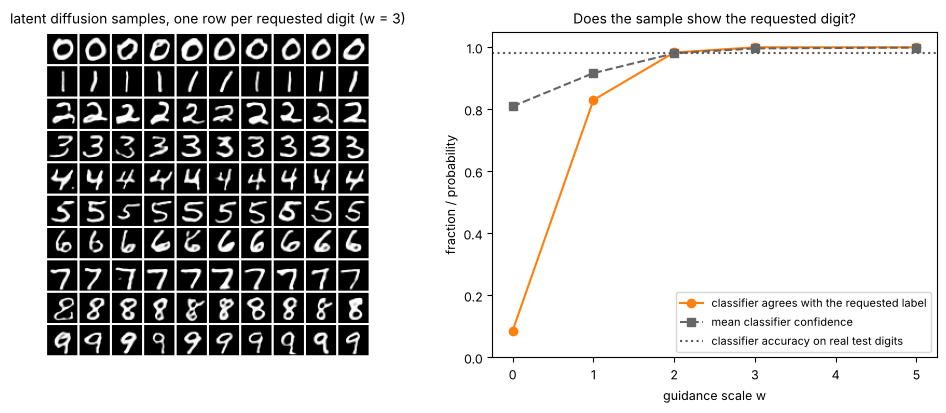

100 samples (50 DDIM steps, CFG) in 8.3s
w = 0.0: agreement 0.087, mean confidence 0.810
w = 1.0: agreement 0.830, mean confidence 0.917
w = 2.0: agreement 0.983, mean confidence 0.980
w = 3.0: agreement 1.000, mean confidence 0.996
w = 5.0: agreement 1.000, mean confidence 0.999


In [9]:
t0 = time.time()
grid = generate(torch.arange(10).repeat_interleave(10), guidance_scale=3.0, seed=0)
t_grid = time.time() - t0

WS = [0.0, 1.0, 2.0, 3.0, 5.0]
y_req = torch.arange(N_EVAL) % 10
acc_w, conf_w = [], []
for w in WS:
    pred, prob = classify(generate(y_req, guidance_scale=w, n_steps=25, seed=123))   # 25 steps suffice here (§7)
    acc_w.append((pred == y_req).float().mean().item())
    conf_w.append(prob.max(1).values.mean().item())

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), gridspec_kw=dict(width_ratios=[1.1, 1]))
dm.show_images(grid, nrow=10, ax=axes[0], title="latent diffusion samples, one row per requested digit (w = 3)")
axes[1].plot(WS, acc_w, "o-", color=C_LAT, label="classifier agrees with the requested label")
axes[1].plot(WS, conf_w, "s--", color="0.4", label="mean classifier confidence")
axes[1].axhline(acc_orig, color=C_REAL, ls=":", label="classifier accuracy on real test digits")
axes[1].set(xlabel="guidance scale w", ylabel="fraction / probability", ylim=(0, 1.05),
            title="Does the sample show the requested digit?")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()
print(f"100 samples (50 DDIM steps, CFG) in {t_grid:.1f}s")
for w, a, c in zip(WS, acc_w, conf_w):
    print(f"w = {w:3.1f}: agreement {a:.3f}, mean confidence {c:.3f}")

Latent diffusion produces recognisable digits from a 7×7×4 latent after a short CPU training run. As in
notebook 06, $w=0$ agrees with the requested label only at chance level (it never sees the label), $w=1$ follows it
most of the time, and guidance pushes agreement and classifier confidence up further. At large $w$ the agreement
reaches or exceeds the classifier's accuracy on *real* test digits: guided samples are more prototypical, and
less diverse, than real data (notebook 06).

**What does the denoiser see?** The top row of the figure below is the latent $z_t$ itself (channel 0, colour scale
$\pm3$); the middle row decodes $z_t$ directly; the bottom row decodes the prediction $\hat z_0(z_t)$ that the DDIM
step computes from the *guided* noise estimate. At $w=1$ this would be the Tweedie posterior mean
$\mathbb E[z_0\mid z_t,y]$ of notebook 03. With $w=3$ it is the extrapolation
$\hat z_0^{u}+w\,(\hat z_0^{c}-\hat z_0^{u})$, which is not the posterior mean of any distribution (notebook 06).

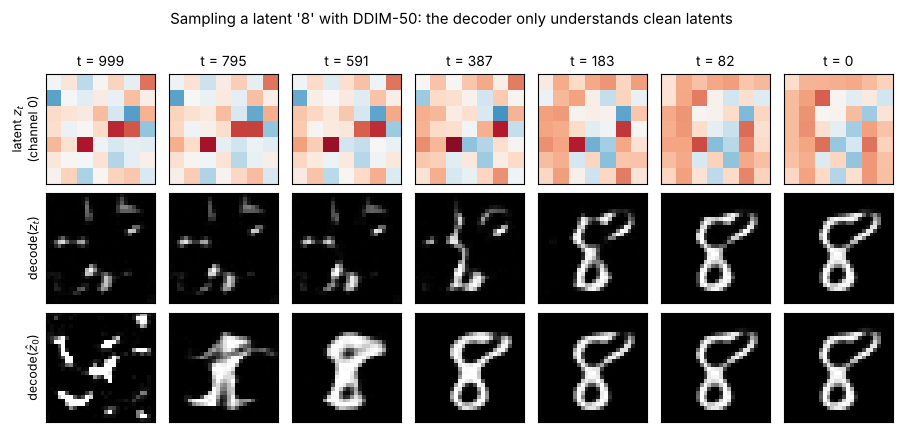

In [10]:
snaps = []
show_at = {0, 10, 20, 30, 40, 45, 49}


def record(i, t, z, z0_hat):
    """Callback: keep (t, z_t, z0_hat) of the first sample at a few steps."""
    if i in show_at:
        snaps.append((t, z[:1].cpu(), z0_hat[:1].cpu()))


_ = generate([8], guidance_scale=3.0, n_steps=50, seed=3, callback=record)
fig, axes = plt.subplots(3, len(snaps), figsize=(1.3 * len(snaps), 4.3))
for j, (t, z, z0) in enumerate(snaps):
    axes[0, j].imshow(z[0, 0], cmap="RdBu_r", vmin=-3, vmax=3)
    axes[0, j].set_title(f"t = {t}")
    axes[1, j].imshow(decode(z / SCALE)[0, 0].cpu().clamp(-1, 1), cmap="gray", vmin=-1, vmax=1)
    axes[2, j].imshow(decode(z0 / SCALE)[0, 0].cpu().clamp(-1, 1), cmap="gray", vmin=-1, vmax=1)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
for r, lab in enumerate(["latent $z_t$\n(channel 0)", "decode($z_t$)", "decode($\\hat z_0$)"]):
    axes[r, 0].set_ylabel(lab)
plt.suptitle("Sampling a latent '8' with DDIM-50: the decoder only understands clean latents", y=1.0)
plt.tight_layout()
plt.show()

Decoding the noisy latent (middle row) gives meaningless fragments for most of the trajectory; only once the noise is
small does it look like a digit. Denoising has to happen in latent space, and only the final, clean latent is
decoded. Decoding $\hat z_0$ (bottom row) shows the coarse-to-fine progression of notebook 05, now in latent space:
the digit's identity is settled early, and later steps only refine it. Diffusers' pipelines decode the latents only
at the very end for the same reason; a live preview of a running generation shows something like the bottom row.

Why is the first $\hat z_0$, at $t=999$, a set of bright fragments rather than a blurry "average digit"? Three
reasons. First, $\hat z_0=(z_t-\sqrt{1-\bar\alpha_t}\,\hat\varepsilon)/\sqrt{\bar\alpha_t}$ multiplies every error in
$\hat\varepsilon$ by $1/\sqrt{\bar\alpha_{999}}\approx157$. Second, guidance with $w=3$ extrapolates. Third, the decoder
is nonlinear and was trained only on clean latents. Even a perfect posterior mean in latent space would not decode
to the posterior mean in pixel space, since $D(\mathbb E[z_0\mid z_t])\neq\mathbb E[D(z_0)\mid z_t]$. The exact
pixel-space posterior mean at high noise is a blurry average digit (notebook 03); a decoded latent estimate carries no
such guarantee.

## 5 · What did the latent space buy us? Speed

We time one training step and one network evaluation (forward pass) for (i) the pixel-space U-Net of notebook 05
(`dm.MNIST_RECIPE`, 1×28×28 input) and (ii) our latent U-Net (4×7×7 input), both with batch 64 and the same
precision. Timing does not depend on the weights, so if the trained pixel checkpoint of notebook 05 is missing we time
an untrained network of the same architecture. The decoder runs once per sample, not once per step, so it is timed
separately. To separate the arithmetic from the hardware, we also count the floating-point operations (FLOPs) of a
forward pass with PyTorch's `FlopCounterMode`, which tallies every convolution, matrix multiply and attention call.

notebook 05's checkpoint not found: timing an untrained U-Net with the same architecture


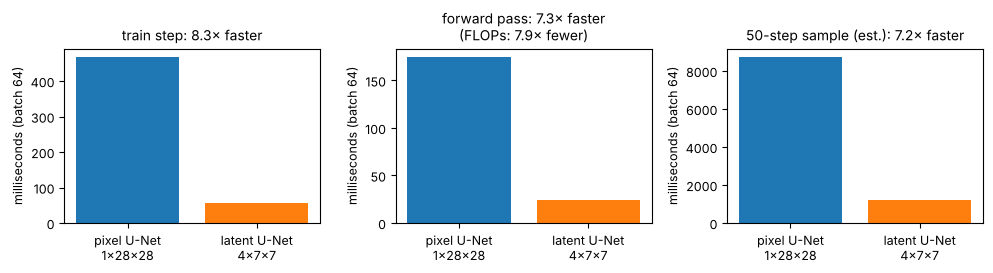

parameters: pixel U-Net 1,191,233, latent U-Net 732,356
FLOPs per forward pass (batch 64): pixel U-Net 24.34 G, latent U-Net 3.08 G -> ratio 7.9x
train step            : pixel    468.2 ms, latent     56.3 ms  -> speed-up 8.3x
forward pass          : pixel    174.8 ms, latent     24.1 ms  -> speed-up 7.3x
50-step sample (est.) : pixel   8737.9 ms, latent   1218.2 ms  -> speed-up 7.2x
decoder: 14.3 ms per batch of 64 (paid once per sample)


In [11]:
def sync():
    """Wait for queued GPU work, so that wall-clock timings are honest."""
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()


def median_time(fn, reps):
    """Median wall-clock seconds of fn() over reps calls, after one warm-up call."""
    fn()
    sync()
    times = []
    for _ in range(reps):
        t0 = time.perf_counter()
        fn()
        sync()
        times.append(time.perf_counter() - t0)
    return float(np.median(times))


def gflops(fn):
    """Billions of floating-point operations in one call of fn(), as counted by torch's FlopCounterMode."""
    from torch.utils.flop_counter import FlopCounterMode
    with FlopCounterMode(display=False) as counter, torch.no_grad():
        fn()
    return counter.get_total_flops() / 1e9


def train_step_fn(model, x, y=None):
    """One full optimiser step (forward, backward, AdamW) on a throw-away copy of the model."""
    m = copy.deepcopy(model).train()
    for p in m.parameters():
        p.requires_grad_(True)
    opt = torch.optim.AdamW(m.parameters(), lr=1e-4)

    def step():
        with autocast():
            loss = dm.diffusion_loss(m, x, schedule, y=y)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
    return step


PIXEL_CKPT = dm.CKPT_DIR / "mnist_unet_uncond.pt"
pixel_trained = PIXEL_CKPT.exists()
if pixel_trained:
    pixel_unet, _ = dm.load_or_train_mnist_model(conditional=False, device=device)
else:
    print("notebook 05's checkpoint not found: timing an untrained U-Net with the same architecture")
    pixel_unet = dm.UNet(**dm.MNIST_RECIPE).to(device).eval()

B, REPS = 64, (2 if FAST else 7)
xb, zb = x_train[:B].to(device), z_train[:B].to(device)
yb = y_train[:B].to(device)
tb = torch.full((B,), 500, device=device, dtype=torch.long)
cost = {"train step": (median_time(train_step_fn(pixel_unet, xb), REPS),
                       median_time(train_step_fn(ldm_ema, zb, yb), REPS))}
with torch.no_grad():
    cost["forward pass"] = (median_time(lambda: pixel_unet(xb, tb), REPS),
                            median_time(lambda: ldm_ema(zb, tb, yb), REPS))
    t_decode = median_time(lambda: decoder(zb), REPS)
# Not measured but estimated: a 50-step sample without CFG is 50 forward passes, plus one decoder call for the latent model.
cost["50-step sample (est.)"] = (50 * cost["forward pass"][0], 50 * cost["forward pass"][1] + t_decode)
flops_pix, flops_lat = gflops(lambda: pixel_unet(xb, tb)), gflops(lambda: ldm_ema(zb, tb, yb))

fig, axes = plt.subplots(1, 3, figsize=(10, 2.8))
for ax, (name, (tp, tl)) in zip(axes, cost.items()):
    ax.bar([0, 1], [1000 * tp, 1000 * tl], color=[C_PIX, C_LAT])
    ax.set_xticks([0, 1], ["pixel U-Net\n1×28×28", "latent U-Net\n4×7×7"])
    extra = f"\n(FLOPs: {flops_pix / flops_lat:.1f}× fewer)" if name == "forward pass" else ""
    ax.set(ylabel="milliseconds (batch 64)", title=f"{name}: {tp / tl:.1f}× faster{extra}")
plt.tight_layout()
plt.show()
n_params = lambda m: sum(p.numel() for p in m.parameters())      # dm.count_params skips frozen (EMA) weights
print(f"parameters: pixel U-Net {n_params(pixel_unet):,}, latent U-Net {n_params(ldm_ema):,}")
print(f"FLOPs per forward pass (batch {B}): pixel U-Net {flops_pix:.2f} G, latent U-Net {flops_lat:.2f} G "
      f"-> ratio {flops_pix / flops_lat:.1f}x")
for name, (tp, tl) in cost.items():
    print(f"{name:22s}: pixel {1000 * tp:8.1f} ms, latent {1000 * tl:8.1f} ms  -> speed-up {tp / tl:.1f}x")
print(f"decoder: {1000 * t_decode:.1f} ms per batch of {B} (paid once per sample)")

The two networks have parameter counts of the same order, but compute is a different matter: a convolution costs
its parameter count times the number of positions it is applied at, and the latent grid has 16× fewer positions.
Why is the FLOP ratio (printed) well below 16×? Two reasons. Our latent U-Net is twice as wide (64 base channels
instead of 32), which makes each of its convolutions about 4× more expensive per position. And the pixel U-Net
already does part of its work at 14×14 and 7×7. Compare the measured forward-pass speed-up with the FLOP ratio:
FLOPs are what the arithmetic demands, wall-clock time is what the hardware delivers. A speed-up larger than the FLOP
ratio means that the pixel model gets fewer FLOPs per second out of the hardware (on a CPU, narrow 32-channel
convolutions over large activations, and the memory-bound normalisation and activation layers between them, are
typically less efficient). A smaller one means that the latent model does (on a GPU, a batch of 4×7×7 latents is too
small to keep the device busy, and fixed per-kernel overheads cap the speed-up). The training step adds costs that do
not shrink with the input at all, since the optimiser update and the mixed-precision casts cost the same per
parameter, and these can pull its speed-up below that of the forward pass. Timings on a shared machine are noisy, even
as medians over several repeats, so read these ratios to within tens of percent.
For Stable Diffusion the arithmetic is far more dramatic: a U-Net at 512×512 instead of 64×64 would need about 64× the compute per step
in its convolutions, and its self-attention layers, whose cost grows with the *square* of the number of positions,
far more. The one-off cost, training the autoencoder, is amortised over every diffusion model
trained on its latents: Stable Diffusion 1.1 to 1.5 all share one autoencoder.

What latent diffusion costs: (i) the autoencoder's reconstruction quality is a ceiling on sample quality, which shows
up in practice as garbled small text and small faces in SD 1.x; (ii) two training stages instead of one; (iii) operations
defined in pixel space (masks, measurements for inverse problems) must be carried into latent space, which is only
approximately possible (we will downsample an inpainting mask in Part B).

In [12]:
if pixel_trained:
    x_T_pix = torch.randn((40, 1, 28, 28), generator=torch.Generator().manual_seed(0)).to(device)
    x_pix = dm.ddim_sample(pixel_unet, schedule, x_T_pix.shape, n_steps=50, x_T=x_T_pix)
    fig, axes = plt.subplots(1, 2, figsize=(10, 2.6))
    dm.show_images(x_pix.cpu(), nrow=10, ax=axes[0], title="pixel-space U-Net (notebook 05), DDIM-50")
    dm.show_images(generate(torch.arange(40) % 10, guidance_scale=0.0, seed=0).cpu(), nrow=10, ax=axes[1],
                   title="latent diffusion, unconditional (w = 0), DDIM-50")
    plt.tight_layout()
    plt.show()
else:
    print("skipping the side-by-side samples: run notebook 05 to create its reference checkpoint")

skipping the side-by-side samples: run notebook 05 to create its reference checkpoint


(When notebook 05's reference checkpoint is available, the cell above shows unconditional samples of the two
models side by side. They were trained with different budgets, so compare them only loosely.)

## 6 · Image-to-image in latent space: SDEdit and the `strength` knob

**SDEdit** (Meng et al. 2022; notebook 07) edits an image by noising it part of the way and then denoising it under
a new condition. Noise to an intermediate step $t_s$ with the forward process,
$z_{t_s}=\sqrt{\bar\alpha_{t_s}}\,z_0+\sqrt{1-\bar\alpha_{t_s}}\,\varepsilon$, then run the reverse sampler from $t_s$
down to 0. Small $t_s$ keeps the layout and details of the input; large $t_s$ keeps only its coarsest features (the
low frequencies survive the longest, notebook 01 §6). In latent space, encode first and decode at the end.

Diffusers' img2img pipelines expose $t_s$ as `strength` $\in[0,1]$: with `num_inference_steps = N` they skip the
first $N-\lfloor N\cdot\text{strength}\rfloor$ timesteps of the sampler's grid and start at the next one. So
`strength=1` starts from (almost) pure noise and ignores the input, and the pipeline only runs
$\lfloor N\cdot\text{strength}\rfloor$ network evaluations. Below: turn test digits into the digit "(label + 3) mod 10"
at increasing strengths.

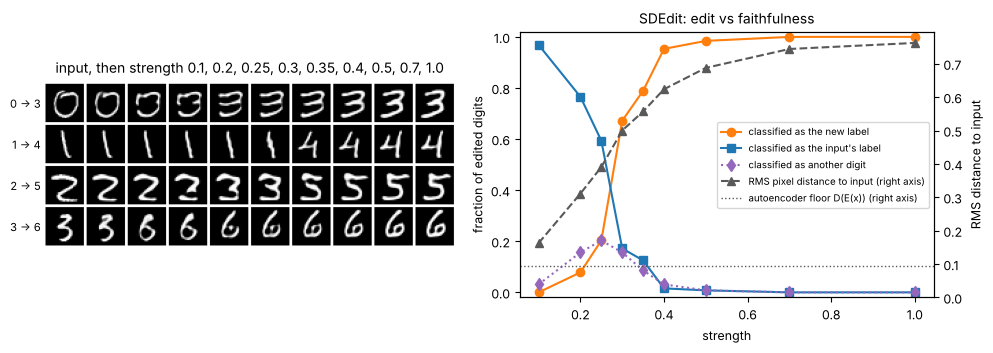

autoencoder floor (RMS distance of D(E(x)) to x): 0.094
strength 0.10 ( 5 of 50 steps): new label 0.00, input's label 0.97, another digit 0.03, distance 0.163
strength 0.20 (10 of 50 steps): new label 0.08, input's label 0.77, another digit 0.16, distance 0.311
strength 0.25 (12 of 50 steps): new label 0.20, input's label 0.59, another digit 0.20, distance 0.391
strength 0.30 (15 of 50 steps): new label 0.67, input's label 0.17, another digit 0.16, distance 0.500
strength 0.35 (17 of 50 steps): new label 0.79, input's label 0.12, another digit 0.09, distance 0.557
strength 0.40 (20 of 50 steps): new label 0.95, input's label 0.02, another digit 0.03, distance 0.624
strength 0.50 (25 of 50 steps): new label 0.98, input's label 0.01, another digit 0.01, distance 0.688
strength 0.70 (35 of 50 steps): new label 1.00, input's label 0.00, another digit 0.00, distance 0.744
strength 1.00 (50 of 50 steps): new label 1.00, input's label 0.00, another digit 0.00, distance 0.762


In [13]:
@torch.no_grad()
def sdedit(x_src, y_target, strength, guidance_scale=3.0, n_steps=50, seed=0):
    """Latent img2img: encode, noise to the strength-dependent timestep, denoise with the new label, decode."""
    grid = ddim_grid(n_steps)
    skip = len(grid) - int(len(grid) * strength)             # diffusers' rule for which steps to skip
    z0 = encode(x_src) * SCALE
    if skip >= len(grid):                                     # strength 0: nothing to do
        return decode(z0 / SCALE).clamp(-1, 1)
    ts = grid[skip:]
    g = torch.Generator().manual_seed(seed)
    noise = torch.randn(z0.shape, generator=g).to(device)
    z = schedule.q_sample(z0, torch.full((len(z0),), ts[0], device=device), noise)   # forward process to t_s (01)
    z = ddim_cfg(ldm_ema, z, torch.as_tensor(y_target, device=device), guidance_scale, ts)
    return decode(z / SCALE).clamp(-1, 1)


def label_rows(ax, labels, size=28, pad=2, fontsize=7):
    """Write one label left of each row of a dm.show_images grid (rows are size + pad pixels apart)."""
    for r, lab in enumerate(labels):
        ax.text(-pad, pad + r * (size + pad) + size / 2, lab, ha="right", va="center", fontsize=fontsize)


STRENGTHS = [0.1, 0.2, 0.25, 0.3, 0.35, 0.4, 0.5, 0.7, 1.0]
n_src = 16 if FAST else 128
x_src, y_src = x_test[2000:2000 + n_src], y_test[2000:2000 + n_src]
y_tgt = (y_src + 3) % 10
edits = {s: sdedit(x_src, y_tgt, s).cpu() for s in STRENGTHS}
frac_tgt = np.array([(classify(edits[s])[0] == y_tgt).float().mean().item() for s in STRENGTHS])
frac_src = np.array([(classify(edits[s])[0] == y_src).float().mean().item() for s in STRENGTHS])
frac_other = 1 - frac_tgt - frac_src                       # neither the input's digit nor the requested one
dist_src = [(edits[s] - x_src).pow(2).mean().sqrt().item() for s in STRENGTHS]
# strength -> 0 returns D(E(x)), so the distance cannot drop below the autoencoder's own reconstruction error
dist_floor = (decode(encode(x_src)).clamp(-1, 1).cpu() - x_src).pow(2).mean().sqrt().item()

fig = plt.figure(figsize=(10, 3.6))
ax = fig.add_subplot(1, 2, 1)
show_idx = [int((y_src == c).nonzero()[0]) for c in y_src.unique()[:4]]   # four inputs with different labels
rows = [torch.cat([x_src[i:i + 1]] + [edits[s][i:i + 1] for s in STRENGTHS]) for i in show_idx]
dm.show_images(torch.cat(rows), nrow=len(STRENGTHS) + 1, ax=ax,
               title="input, then strength " + ", ".join(map(str, STRENGTHS)))
label_rows(ax, [f"{y_src[i].item()} → {y_tgt[i].item()}" for i in show_idx], fontsize=8)
ax = fig.add_subplot(1, 2, 2)
ax.plot(STRENGTHS, frac_tgt, "o-", color=C_LAT, label="classified as the new label")
ax.plot(STRENGTHS, frac_src, "s-", color=C_PIX, label="classified as the input's label")
ax.plot(STRENGTHS, frac_other, "d:", color="tab:purple", label="classified as another digit")
ax.set(xlabel="strength", ylabel="fraction of edited digits", ylim=(-0.02, 1.02), title="SDEdit: edit vs faithfulness")
ax2 = ax.twinx()
ax2.plot(STRENGTHS, dist_src, "^--", color=C_REAL, label="RMS pixel distance to input (right axis)")
ax2.axhline(dist_floor, color=C_REAL, ls=":", lw=1, label="autoencoder floor D(E(x)) (right axis)")
ax2.set(ylabel="RMS distance to input", ylim=(0, None))
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="center right", fontsize=7)
plt.tight_layout()
plt.show()
print(f"autoencoder floor (RMS distance of D(E(x)) to x): {dist_floor:.3f}")
for s, a, b, o, d in zip(STRENGTHS, frac_tgt, frac_src, frac_other, dist_src):
    print(f"strength {s:.2f} ({int(50 * s):2d} of 50 steps): new label {a:.2f}, input's label {b:.2f}, "
          f"another digit {o:.2f}, distance {d:.3f}")

`strength` trades faithfulness for editability. At low strength the output keeps the input's identity (blue
curve high) and stays close to it in pixels, although never closer than the autoencoder allows (dotted line). At high
strength the new label wins (orange curve), and the output keeps less and less of the input, until at `strength=1`
it is unrelated to it. The switch happens over a narrow range of strengths, where the noise level reaches the scale
of the features that distinguish the two digits; there the coarse shape of the input (position, slant, thickness)
survives while the identity changes. In that range some edits are neither digit (purple curve): the sampler, pulled
between the input's shape and the new label, settles on a third digit that is compatible with both, as some rows of
the image grid may show.
Where exactly that range lies depends on the schedule, the step grid and the guidance scale, which is why
img2img users tune `strength` per image. Stable Diffusion's img2img does exactly this, with text instead of
labels.

## 7 · Bridge: our model under 🤗 diffusers' schedulers

In diffusers, a **scheduler** is the sampler of notebook 04 as a small state machine, separate from the network:

```python
scheduler.set_timesteps(num_inference_steps)    # choose the grid of t's (and reset the internal state)
z = z_T * scheduler.init_noise_sigma            # 1 for DDIM; sigma_max for samplers that work with x / sqrt(abar)
for t in scheduler.timesteps:
    model_in = scheduler.scale_model_input(z, t)          # back to the VP scale the network was trained on
    eps = network(model_in, t)
    z = scheduler.step(eps, t, z).prev_sample             # one sampler update
```

Its training schedule is given by a few config numbers: `num_train_timesteps`, `beta_schedule`, `beta_start`,
`beta_end`, `prediction_type`. Because the API is model-agnostic, we can drive **our** MNIST latent model with
diffusers' schedulers on a CPU, with no download. The cells of this section need only `pip install diffusers`, no GPU;
without it they print an install hint instead of the results discussed below. We check that:

1. `DDIMScheduler` with our schedule reproduces our hand-written `ddim_cfg` on the same timesteps;
2. `EulerDiscreteScheduler` on the same timesteps gives the same samples too. Euler works with
   $x/\sqrt{\bar\alpha}$ and the noise level $\sigma=\sqrt{(1-\bar\alpha)/\bar\alpha}$ (the variance-exploding form of
   notebook 01 §9), which is why it starts at `init_noise_sigma` $=\sigma_{\max}$ and rescales its input with
   `scale_model_input` $=x/\sqrt{\sigma^2+1}$. A DDIM step *is* an Euler step of the probability-flow ODE in
   these coordinates (notebook 04 §3.2);
3. how fast each sampler converges to the exact ODE solution as the number of network evaluations (NFE) grows.

In [14]:
@torch.no_grad()
def diffusers_sample(model, scheduler, z_T, y, w, n_steps=None, timesteps=None):
    """The Stable Diffusion sampling loop (Part B), with our latent MNIST model as the network."""
    y_in = torch.cat([torch.full_like(y, model.n_classes), y])            # [uncond | cond]
    if timesteps is None:
        scheduler.set_timesteps(n_steps, device=device)
    else:
        scheduler.set_timesteps(timesteps=timesteps, device=device)       # Euler/DPM accept an explicit grid
    z = z_T * scheduler.init_noise_sigma
    for t in scheduler.timesteps:
        z_in = scheduler.scale_model_input(torch.cat([z, z]), t)
        t_in = t.to(device).float().expand(len(z_in))                      # Euler's timesteps can be fractional
        eps_u, eps_c = model(z_in, t_in, y_in).chunk(2)
        z = scheduler.step(eps_u + w * (eps_c - eps_u), t, z).prev_sample
    return z


if HAVE_DIFFUSERS:
    import diffusers
    from diffusers import DDIMScheduler, DPMSolverMultistepScheduler, EulerDiscreteScheduler
    print(f"diffusers {diffusers.__version__}")
    # Our training schedule, in diffusers' config language.
    OUR_SCHEDULE = dict(num_train_timesteps=1000, beta_schedule="linear", beta_start=1e-4, beta_end=0.02,
                        prediction_type="epsilon")
    # clip_sample=False: DDIMScheduler's default clips x0-predictions to [-1, 1] (notebook 05's x0-clipping), right for
    # pixels but wrong for unit-variance latents. SD's config sets it to False too.
    make_ddim = lambda spacing: DDIMScheduler(**OUR_SCHEDULE, clip_sample=False, set_alpha_to_one=True,
                                              timestep_spacing=spacing)
    ddim_s = make_ddim("trailing")
    assert torch.allclose(ddim_s.alphas_cumprod.to(device), schedule.alpha_bars, atol=1e-6)

    n_cmp = 8 if FAST else 32
    y_cmp = (torch.arange(n_cmp) % 10).to(device)
    z_T = torch.randn((n_cmp, Z_CH, LAT, LAT), generator=torch.Generator().manual_seed(7)).to(device)
    z_hf = diffusers_sample(ldm_ema, ddim_s, z_T, y_cmp, 3.0, n_steps=10)
    grid_hf = ddim_s.timesteps.tolist()
    z_mine = ddim_cfg(ldm_ema, z_T, y_cmp, 3.0, grid_hf)
    z_euler = diffusers_sample(ldm_ema, EulerDiscreteScheduler(**OUR_SCHEDULE), z_T, y_cmp, 3.0, timesteps=grid_hf)
    print(f"DDIMScheduler timesteps: {grid_hf}")
    rel = lambda a, b: ((a - b).pow(2).mean() / b.pow(2).mean()).sqrt().item()   # relative RMS difference
    print(f"DDIMScheduler vs our ddim_cfg:          max |diff| {(z_hf - z_mine).abs().max().item():.1e}, "
          f"relative RMS {rel(z_hf, z_mine):.1e}")
    print(f"EulerDiscreteScheduler vs DDIMScheduler: max |diff| {(z_euler - z_hf).abs().max().item():.1e}, "
          f"relative RMS {rel(z_euler, z_hf):.1e}")
    assert rel(z_hf, z_mine) < 1e-3 and rel(z_euler, z_hf) < 1e-2
else:
    print("diffusers is not installed: `pip install diffusers` (CPU is fine, nothing is downloaded) to run §7")

diffusers 0.43.0


DDIMScheduler timesteps: [999, 899, 799, 699, 599, 499, 399, 299, 199, 99]
DDIMScheduler vs our ddim_cfg:          max |diff| 1.0e-05, relative RMS 7.0e-07
EulerDiscreteScheduler vs DDIMScheduler: max |diff| 1.5e-03, relative RMS 4.0e-05


Both checks pass: the scheduler is notebook 04's arithmetic, packaged. (The small Euler–DDIM difference is
floating-point rounding, since Euler's variable $x/\sqrt{\bar\alpha}$ is up to $\sigma_{\max}\approx160$ times
larger, plus the fact that Euler starts at exactly $\sigma_{\max}$ rather than at $\sqrt{\sigma_{\max}^2+1}$.)

**Two silent bugs, shown.** The gotchas of §2.3 and of the comment above produce images without any error message.
Below, the same $z_T$ and the same 25-step DDIM sampler three times: done correctly; with the generated latents
decoded *without* dividing by the scale factor $c$; and with `DDIMScheduler`'s default `clip_sample=True`, which
clamps the predicted $\hat z_0$ to $[-1,1]$ at every step. For pixels that is notebook 05's useful $x_0$-clipping,
but a sizeable fraction of unit-variance latent values lies outside $[-1,1]$ (printed).

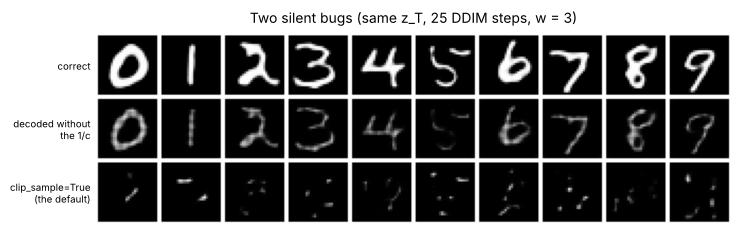

fraction of scaled training latents outside [-1, 1]: 0.30


In [15]:
if HAVE_DIFFUSERS:
    k = min(10, len(z_T))                                          # images per row
    z_ok = diffusers_sample(ldm_ema, make_ddim("trailing"), z_T[:k], y_cmp[:k], 3.0, n_steps=25)
    # the same sampler, but with clip_sample left at DDIMScheduler's default
    clipping_ddim = DDIMScheduler(**OUR_SCHEDULE, set_alpha_to_one=True, timestep_spacing="trailing")
    z_clip = diffusers_sample(ldm_ema, clipping_ddim, z_T[:k], y_cmp[:k], 3.0, n_steps=25)
    rows = torch.cat([decode(z_ok / SCALE), decode(z_ok), decode(z_clip / SCALE)]).clamp(-1, 1).cpu()
    fig, ax = plt.subplots(figsize=(7.5, 2.7))
    dm.show_images(rows, nrow=k, ax=ax, title="Two silent bugs (same z_T, 25 DDIM steps, w = 3)")
    label_rows(ax, ["correct", "decoded without\nthe 1/c",
                    f"clip_sample={clipping_ddim.config.clip_sample}\n(the default)"])
    plt.tight_layout()
    plt.show()
    print(f"fraction of scaled training latents outside [-1, 1]: {(z_train.abs() > 1).float().mean().item():.2f}")
else:
    print("diffusers is not installed: `pip install diffusers` to run §7")

Without the $1/c$, the decoder receives latents shrunk by the factor $c$ and renders faint, washed-out strokes.
Clipping is far more destructive: at every step it truncates the large latent values that carry the digit's
shape, and the samples fall apart. Neither bug raises an error, which is what makes them classic.

Now the comparison that matters in practice: sample quality versus cost. Every deterministic sampler here
approximately solves the same probability-flow ODE, that of *our learned network*, from the same $z_T$. So we can
measure each sampler's **discretisation error** against a very fine solution (a 200-step DPM-Solver++ run from the
same noise) without knowing the true data distribution. Model and sampler are not completely separable, though: how
large the error of a coarse step is depends on how accurate and smooth the learned field is along that step, and we
will meet an example. Each sampler uses its default timestep grid, and we include DDIM twice. For $N=4$ network calls:

* **"trailing"** timesteps start at $t=T-1$: $\{999, 749, 499, 249\}$;
* **"leading"** timesteps (the default of `DDIMScheduler`, and SD 1.5's config) are $\{0, T/N, 2T/N, \dots\}$
  reversed (plus `steps_offset`): $\{750, 500, 250, 0\}$. The sampler never evaluates the network at $t=999$: it
  starts from pure noise but tells the network that it is at $t=750$, a flaw pointed out by Lin et al. (2024). Its
  last call, at $t=0$, has almost no noise left to remove;
* Euler's default **"linspace"** grid, $\{999, 666, 333, 0\}$, has both a call at $t=999$ and one at $t=0$. It is
  exactly the grid of `dm.ddim_sample` and of our `ddim_grid` (printed below). So the Euler curve is also the error
  of the sampler we used in §4 and §6, and in notebooks 04–08.

DDIM (trailing)            4-step grid: [999, 749, 499, 249]
DDIM (leading)             4-step grid: [750, 500, 250, 0]
Euler (linspace grid)      4-step grid: [999, 666, 333, 0]
DPM-Solver++ (2M)          4-step grid: [999, 749, 500, 250]
dm.ddim_sample, ddim_grid  4-step grid: [999, 666, 333, 0]


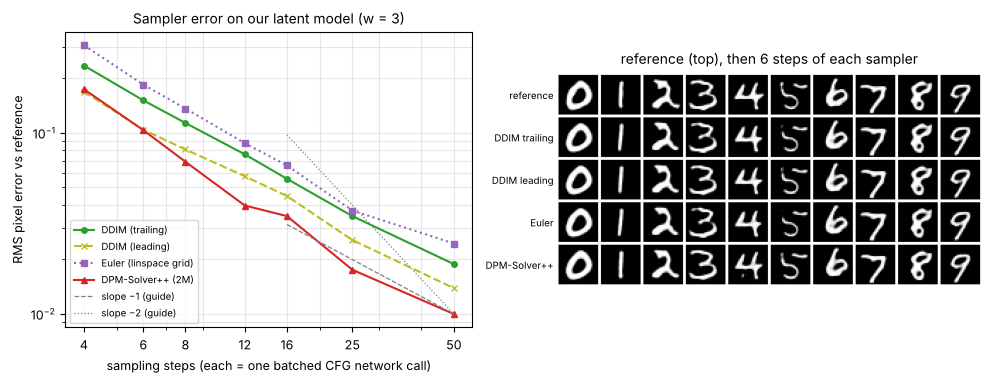

DDIM (trailing)       : 4:0.236  6:0.151  8:0.113  12:0.076  16:0.056  25:0.035  50:0.019
DDIM (leading)        : 4:0.169  6:0.104  8:0.081  12:0.058  16:0.045  25:0.026  50:0.014
Euler (linspace grid) : 4:0.305  6:0.185  8:0.136  12:0.088  16:0.066  25:0.037  50:0.024
DPM-Solver++ (2M)     : 4:0.174  6:0.104  8:0.069  12:0.040  16:0.035  25:0.018  50:0.010
fitted slopes of log(error) vs log(steps): DDIM (trailing) -1.01, DDIM (leading) -0.98, Euler (linspace grid) -1.02, DPM-Solver++ (2M) -1.14
4 steps: trailing 0.236 | trailing without its first step (the one from t=999) 0.170 | leading 0.169
6 steps: trailing 0.151 | trailing without its first step (the one from t=999) 0.110 | leading 0.104
one DDIM step 999 -> 749: z_749 = 9.11 z_999 -8.11 eps_hat, so an error in eps_hat at t=999 is multiplied by 8.1
leading grid, 4 steps: first t = 750; corr(z_t, z_0) there = 0.057 under our schedule vs 0.237 under SD's (pure noise: 0)
leading grid, 8 steps: first t = 875; corr(z_t, z_0) there = 0

In [16]:
if HAVE_DIFFUSERS:
    NFES = [4, 8] if FAST else [4, 6, 8, 12, 16, 25, 50]
    samplers = {
        "DDIM (trailing)": (lambda: make_ddim("trailing"), "tab:green", "o-"),
        "DDIM (leading)": (lambda: make_ddim("leading"), "tab:olive", "x--"),
        "Euler (linspace grid)": (lambda: EulerDiscreteScheduler(**OUR_SCHEDULE), "tab:purple", "s:"),
        "DPM-Solver++ (2M)": (lambda: DPMSolverMultistepScheduler(**OUR_SCHEDULE), "tab:red", "^-"),
    }
    for name, (make, _, _) in samplers.items():                 # each scheduler's default grid for 4 steps
        sch = make()
        sch.set_timesteps(4)
        print(f"{name:26s} 4-step grid: {[round(float(t)) for t in sch.timesteps]}")
    print(f"{'dm.ddim_sample, ddim_grid':26s} 4-step grid: {ddim_grid(4)}")

    x_ref = decode(diffusers_sample(ldm_ema, DPMSolverMultistepScheduler(**OUR_SCHEDULE), z_T, y_cmp, 3.0,
                                    n_steps=20 if FAST else 200) / SCALE).clamp(-1, 1)
    rms_to_ref = lambda z: (decode(z / SCALE).clamp(-1, 1) - x_ref).pow(2).mean().sqrt().item()
    errors, imgs_at = {}, {}
    for name, (make, _, _) in samplers.items():
        errors[name] = []
        for n in NFES:
            z_n = diffusers_sample(ldm_ema, make(), z_T, y_cmp, 3.0, n_steps=n)
            errors[name].append(rms_to_ref(z_n))
            if n == NFES[1]:
                imgs_at[name] = decode(z_n[:10] / SCALE).clamp(-1, 1).cpu()
    # Mechanism check (discussed below): the trailing grid with its first step, from t = 999, skipped,
    # i.e. z_T is used as if it were z at the second grid point.
    skip_first = []
    for n in NFES[:2]:
        sch = make_ddim("trailing")
        sch.set_timesteps(n)
        skip_first.append(rms_to_ref(ddim_cfg(ldm_ema, z_T, y_cmp, 3.0, sch.timesteps.tolist()[1:])))

    fig, axes = plt.subplots(1, 2, figsize=(10, 3.9), gridspec_kw=dict(width_ratios=[1, 1.05]))
    ax = axes[0]
    for name, (_, c, style) in samplers.items():
        ax.plot(NFES, errors[name], style, color=c, label=name, ms=4)
    # slope guides through DPM-Solver++'s last point: first-order methods fall like 1/N, second-order like 1/N^2
    n_g = np.array(NFES[-3:], dtype=float)
    e_end = errors["DPM-Solver++ (2M)"][-1]
    ax.plot(n_g, e_end * (n_g / n_g[-1]) ** -1.0, color="0.5", lw=0.9, ls="--", label="slope −1 (guide)")
    ax.plot(n_g, e_end * (n_g / n_g[-1]) ** -2.0, color="0.5", lw=0.9, ls=":", label="slope −2 (guide)")
    ax.set(xscale="log", yscale="log", xlabel="sampling steps (each = one batched CFG network call)",
           ylabel="RMS pixel error vs reference", title="Sampler error on our latent model (w = 3)")
    ax.set_xticks(NFES, [str(n) for n in NFES])
    ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
    ax.legend(loc="lower left", fontsize=7)
    ax.grid(alpha=0.3, which="both")
    rows = torch.cat([x_ref[:10].cpu()] + [imgs_at[name] for name in samplers])
    dm.show_images(rows, nrow=len(x_ref[:10]), ax=axes[1], title=f"reference (top), then {NFES[1]} steps of each sampler")
    label_rows(axes[1], ["reference", "DDIM trailing", "DDIM leading", "Euler", "DPM-Solver++"])
    plt.tight_layout()
    plt.show()
    for name in samplers:
        print(f"{name:22s}: " + "  ".join(f"{n}:{e:.3f}" for n, e in zip(NFES, errors[name])))
    slopes = {name: -np.polyfit(np.log(NFES), np.log(errors[name]), 1)[0] for name in samplers}
    print("fitted slopes of log(error) vs log(steps): " + ", ".join(f"{k} -{v:.2f}" for k, v in slopes.items()))
    for n, e_skip, e_tr, e_ld in zip(NFES[:2], skip_first, errors["DDIM (trailing)"], errors["DDIM (leading)"]):
        print(f"{n} steps: trailing {e_tr:.3f} | trailing without its first step (the one from t=999) {e_skip:.3f} "
              f"| leading {e_ld:.3f}")
    t1 = 999 - 1000 // 4                                   # second point of the 4-step trailing grid
    c_z = np.sqrt(abar_ours[t1] / abar_ours[999])
    c_eps = np.sqrt(1 - abar_ours[t1]) - c_z * np.sqrt(1 - abar_ours[999])
    print(f"one DDIM step 999 -> {t1}: z_{t1} = {c_z:.2f} z_999 {c_eps:+.2f} eps_hat, "
          f"so an error in eps_hat at t=999 is multiplied by {abs(c_eps):.1f}")
    # How much signal does the first "leading" timestep claim? For unit-variance data corr(z_t, z_0) = sqrt(abar_t).
    for n in (4, 8):
        t1 = (n - 1) * (1000 // n)
        print(f"leading grid, {n} steps: first t = {t1}; corr(z_t, z_0) there = {np.sqrt(abar_ours[t1]):.3f} "
              f"under our schedule vs {np.sqrt(abar_sd[t1]):.3f} under SD's (pure noise: 0)")

At 6 steps the samples of all four samplers already look much alike (right); the curves quantify the differences.
Practical lessons, all on a model we trained ourselves:

* **The grid matters as much as the solver.** DDIM and Euler are the same first-order method (the check above), so
  the three first-order curves are one solver on three grids, and at few steps their errors differ substantially.
* **Why does "leading" beat "trailing" here?** DDIM always steps from $t$ to $t-T/N$, so the two grids call the
  network at practically the same noise levels. The only differences are trailing's extra call at $t=999$ and
  leading's nearly useless one at $t=0$. The printed check isolates the culprit: trailing *without* its first step
  ($z_T$ used as if it were $z_{749}$) has nearly the same error as leading. So the step from $t=999$ hurts. The DDIM
  update from $t=999$ to $t_1$ reads
  $$z_{t_1}=\sqrt{\bar\alpha_{t_1}/\bar\alpha_{999}}\;z_{999}+\Big(\sqrt{1-\bar\alpha_{t_1}}-\sqrt{\bar\alpha_{t_1}/\bar\alpha_{999}}\,\sqrt{1-\bar\alpha_{999}}\Big)\,\hat\varepsilon,$$
  and the coefficient of $\hat\varepsilon$ is large (printed). Any error of the network at $t=999$ is amplified by
  it, and any error in the guidance direction $\hat\varepsilon_c-\hat\varepsilon_u$ by $w$ times more. With the *exact* score this single coarse step would be
  nearly exact; with a learned $\hat\varepsilon$ it is the least reliable step of the trajectory. Predicting
  $\varepsilon$ is ill-conditioned at very low SNR: there $\varepsilon\approx z_t$, and all the information about $z_0$
  sits in a correction of relative size $\sqrt{\bar\alpha_{999}}\approx0.006$. This is one motivation for
  $v$-prediction (Salimans & Ho 2022) and for zero-terminal-SNR schedules (Lin et al. 2024). Under our schedule,
  skipping the segment from 999 to 750 costs almost nothing, because almost no signal is left there (printed).
* **...but under SD's schedule "leading" is the wrong choice.** Under SD's "scaled_linear" schedule a clearly
  non-zero correlation with the data remains at the first leading timestep (printed). The leading sampler therefore
  starts from a distribution the network does not expect. That is the flaw Lin et al. (2024) identified, and why
  `timestep_spacing="trailing"` is recommended for few-step sampling with SD-like schedules. The general rule: check
  what the first timestep means under *your* schedule, and how reliable your network is there.
* **DPM-Solver++ (2M)** (Lu et al. 2022), a second-order multistep solver, has the smallest error for most step
  counts. That is why 20–25 DPM-Solver++ steps are a common default for Stable Diffusion, instead of 50 DDIM or PNDM
  steps. Yet its fitted slope (printed) is close to that of the first-order methods, about 1 rather than 2 (compare
  the guides): here it wins by a constant factor, not by a visibly higher order. The main reason is its last step. From
  the last grid point, $t\approx T/N$, diffusers jumps straight to $\sigma=0$ with a first-order update
  (`final_sigmas_type="zero"`), and on a grid that is uniform in $t$ that final jump is long enough to dominate the
  error. Exercise 4 moves steps towards low noise.

# Part B · Stable Diffusion with 🤗 diffusers

Everything from here on uses real Stable Diffusion 1.5 weights, about 1 B parameters in total. It needs:

* a CUDA GPU with ≥ 6 GB of memory (fp16), or an Apple-silicon Mac (MPS; slower). On a CPU it would take minutes
  per image, so the code refuses to run there;
* internet access to the Hugging Face Hub. The first call downloads the weights (several GB) into
  `~/.cache/huggingface`;
* `pip install "diffusers>=0.43" "transformers>=5.23" "accelerate>=1.16"`. This notebook's Part B was written against
  **diffusers 0.43.0, transformers 5.23.0 and accelerate 1.16.0**; every class, method and argument used below was
  checked against those versions. If a newer release breaks something, install exactly these with
  `pip install diffusers==0.43.0 transformers==5.23.0 accelerate==1.16.0`. The model weights could not be downloaded when this notebook was prepared, so Part B
  has not been run with the real model, and the descriptions of its outputs say what to expect, not what was
  measured. The code itself was run end to end on a tiny, randomly initialised pipeline built from the same
  component classes, where the hand-written loop of B.3 reproduced `pipe(...)` exactly.

Set `RUN_SD = True` in the next cell to run Part B. With `RUN_SD = False` (the default), the cells only print a
message, so the notebook still runs top to bottom anywhere.

In [17]:
RUN_SD = False   # <- set to True on a machine with a GPU and Hugging Face Hub access

SD_OK = RUN_SD and HAVE_DIFFUSERS and HAVE_TRANSFORMERS and device.type in ("cuda", "mps")
if RUN_SD and not SD_OK:
    print("RUN_SD=True, but Part B needs `pip install diffusers transformers accelerate` and a CUDA or MPS device.")
print(f"Part B will {'run' if SD_OK else 'be skipped'}  (RUN_SD={RUN_SD}, diffusers installed={HAVE_DIFFUSERS}, "
      f"transformers installed={HAVE_TRANSFORMERS}, device={device.type})")
SD_MODEL = "stable-diffusion-v1-5/stable-diffusion-v1-5"
SD_DTYPE = torch.float16         # halves memory and doubles speed on GPUs; see B.7 for bfloat16
PROMPT = "a watercolor painting of a red fox reading a book under an oak tree, soft morning light"


def show_pils(images, titles=None, ncols=4, size=3.0, suptitle=None):
    """Show PIL images, or (B,3,H,W) / (3,H,W) tensors in [0, 1], in a grid."""
    ims = []
    for im in images:
        if torch.is_tensor(im):
            ims.extend(list(im.float().cpu().reshape(-1, *im.shape[-3:]).permute(0, 2, 3, 1).numpy()))
        else:
            ims.append(np.asarray(im))
    nrows = math.ceil(len(ims) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows), squeeze=False)
    for i, ax in enumerate(axes.flat):
        ax.set_axis_off()
        if i < len(ims):
            ax.imshow(ims[i])
            if titles:
                ax.set_title(titles[i], fontsize=8)
    if suptitle:
        fig.suptitle(suptitle, fontsize=9)
    plt.tight_layout()
    plt.show()

Part B will be skipped  (RUN_SD=False, diffusers installed=True, transformers installed=True, device=cpu)


## B.1 · Text to image in three lines

`AutoPipelineForText2Image` reads the model repository's config and builds the right pipeline class (here
`StableDiffusionPipeline`). Two habits worth keeping: load in **fp16**, and pass a seeded `torch.Generator`. A
**CPU** generator gives the same image for the same seed on any GPU; a CUDA generator's random stream depends on
the hardware.

*What you will see:* four 512×512 images of the prompt, different for each sample in the batch but identical every
time you re-run the cell. On a recent GPU the 30 steps take a few seconds per image.

In [18]:
if SD_OK:
    from diffusers import AutoPipelineForText2Image
    pipe = AutoPipelineForText2Image.from_pretrained(SD_MODEL, torch_dtype=SD_DTYPE).to(device)
    pipe.set_progress_bar_config(disable=True)
    t0 = time.time()
    images = pipe(PROMPT, num_inference_steps=30, guidance_scale=7.5, num_images_per_prompt=4,
                  generator=torch.Generator("cpu").manual_seed(0)).images
    print(f"{type(pipe).__name__}: {len(images)} images of size {images[0].size} in {time.time() - t0:.1f}s")
    show_pils(images, suptitle=PROMPT)
else:
    print("Part B skipped (set RUN_SD = True)")

Part B skipped (set RUN_SD = True)


## B.2 · Anatomy: the pipeline is the parts of this tutorial

A pipeline is a thin wrapper around its `components`.

| component | class | role | notebook |
|---|---|---|---|
| `tokenizer`, `text_encoder` | `CLIPTokenizer`, `CLIPTextModel` (CLIP ViT-L/14 text tower) | prompt → 77 token embeddings of size 768, the condition $y$ | 06 |
| `unet` | `UNet2DConditionModel` (~860 M parameters) | $\varepsilon_\theta(z_t, t, y)$ on 4×64×64 latents; text enters through cross-attention layers in most blocks | 02, 05 |
| `vae` | `AutoencoderKL` ($f=8$, 4 channels, `scaling_factor` 0.18215) | §2 of this notebook | 09 |
| `scheduler` | `PNDMScheduler` by default; "scaled_linear" betas from 0.00085 to 0.012, $T=1000$ | the sampler | 01, 04 |
| `safety_checker`, `feature_extractor` | a CLIP-based NSFW image classifier | blacks out flagged images | — |

Cross-attention generalises the class embedding of our U-Net: the queries come from the latent's spatial positions,
the keys and values from the 77 text tokens, so different image regions can attend to different words.

*What you will see:* the list of components with their parameter counts (U-Net about 860 M, text encoder about
123 M, VAE about 84 M) and the scheduler's configuration, including `beta_schedule='scaled_linear'`,
`prediction_type='epsilon'`, `timestep_spacing='leading'` and `steps_offset=1`.

In [19]:
if SD_OK:
    for name, comp in pipe.components.items():
        if comp is None:                                 # optional components this pipeline does not use
            continue
        n_par = f"{sum(p.numel() for p in comp.parameters()) / 1e6:8.1f} M params" if isinstance(comp, nn.Module) else ""
        print(f"{name:18s} {type(comp).__name__:32s} {n_par}")
    print("latent channels:", pipe.unet.config.in_channels, "| latent size:", pipe.unet.config.sample_size,
          "| VAE downsampling factor:", pipe.vae_scale_factor, "| VAE scaling factor:", pipe.vae.config.scaling_factor)
    print("text: max tokens", pipe.tokenizer.model_max_length, "| embedding size", pipe.text_encoder.config.hidden_size)
    keys = ["num_train_timesteps", "beta_schedule", "beta_start", "beta_end", "prediction_type",
            "timestep_spacing", "steps_offset"]
    print("scheduler config:", {k: pipe.scheduler.config.get(k) for k in keys})
else:
    print("Part B skipped (set RUN_SD = True)")

Part B skipped (set RUN_SD = True)


## B.3 · The sampling loop, by hand

Below is the whole of `pipe(...)` in about fifteen lines, written with the components. Compare it line by line with
`generate` in §4 and `diffusers_sample` in §7: the only new piece is the text encoder. The comment on each line names
the notebook it comes from.

The check runs the pipeline and the hand-written loop from the **same** initial latents with the same DDIM scheduler.
*What you will see:* two visually identical images, and a printed maximum pixel difference close to zero
(exactly zero, or at the level of fp16 rounding if the GPU uses non-deterministic kernels).

In [20]:
@torch.no_grad()
def encode_text(prompts):
    """Prompts -> CLIP token embeddings (B, 77, 768): the condition y of notebook 06, now a sequence."""
    tok = pipe.tokenizer(prompts, padding="max_length", max_length=pipe.tokenizer.model_max_length,
                         truncation=True, return_tensors="pt")
    return pipe.text_encoder(tok.input_ids.to(device))[0]                       # last hidden state


@torch.no_grad()
def sd_sample(prompt, negative_prompt="", scheduler=None, steps=30, guidance_scale=7.5, seed=0, latents=None,
              height=512, width=512):
    """Text -> image with Stable Diffusion, written out. Returns a (1, 3, H, W) tensor in [0, 1]."""
    unet, vae, sch = pipe.unet, pipe.vae, scheduler or pipe.scheduler
    emb = torch.cat([encode_text([negative_prompt]), encode_text([prompt])])    # [uncond | cond]          (06)
    if latents is None:
        f = pipe.vae_scale_factor
        latents = torch.randn((1, unet.config.in_channels, height // f, width // f),
                              generator=torch.Generator("cpu").manual_seed(seed), dtype=emb.dtype)
    sch.set_timesteps(steps, device=device)                                      # sub-sampled grid         (04)
    # init_noise_sigma AFTER set_timesteps: for Euler-type schedulers it is sigma_max of the grid just chosen
    z = latents.to(device) * sch.init_noise_sigma                                # z_T ~ N(0, I)            (02)
    for t in sch.timesteps:
        z_in = sch.scale_model_input(torch.cat([z, z]), t)                       # VE <-> VP scaling        (01 §9)
        eps_u, eps_c = unet(z_in, t, encoder_hidden_states=emb).sample.chunk(2)  # eps-prediction U-Net     (02, 05)
        eps = eps_u + guidance_scale * (eps_c - eps_u)                           # classifier-free guidance (06)
        z = sch.step(eps, t, z).prev_sample                                      # sampler update           (04)
    image = vae.decode(z / vae.config.scaling_factor).sample                     # undo scale, decode       (09 §2)
    return (image / 2 + 0.5).clamp(0, 1)                                         # [-1, 1] -> [0, 1]


if SD_OK:
    from diffusers import DDIMScheduler
    # swap the sampler (B.4); an explicit clip_sample=False guards against DDIMScheduler's default (§7, B.4)
    pipe.scheduler = DDIMScheduler.from_config(pipe.scheduler.config, clip_sample=False)
    z_T = torch.randn((1, 4, 64, 64), generator=torch.Generator("cpu").manual_seed(1), dtype=SD_DTYPE)
    mine = sd_sample(PROMPT, steps=30, latents=z_T)
    theirs = pipe(PROMPT, num_inference_steps=30, guidance_scale=7.5, latents=z_T, output_type="pt").images
    print(f"max |hand-written - pipeline| = {(mine.float() - theirs.float().to(mine.device)).abs().max().item():.4f}"
          " (pixel values in [0, 1])")
    show_pils([mine, theirs], ["hand-written loop", "pipe(...)"], ncols=2, size=4)
else:
    print("Part B skipped (set RUN_SD = True)")

Part B skipped (set RUN_SD = True)


## B.4 · Swapping samplers and step counts

Schedulers are interchangeable because they share the training-schedule config:
`NewScheduler.from_config(pipe.scheduler.config)` builds a different sampler for the *same* trained network. Extra
keyword arguments override the config, e.g. `DDIMScheduler.from_config(cfg, timestep_spacing="trailing")`. Note
that `from_config` carries over only the keys that were set *explicitly* in the source config. Keys that were merely
the source class's defaults (listed in `config._use_default_values`) are not carried over, and the new class uses its
own default. For example, SD 1.5's config does not set `timestep_spacing`, so Euler and DPM-Solver++ built from it
start on their default "linspace" grid and DDIM on "leading". Passing `clip_sample=False` to DDIM is a defensive
habit: SD 1.5's config already contains it (and `StableDiffusionPipeline` enforces it), but for a config that lacks
the key, `DDIMScheduler` falls back to its own default, `clip_sample=True`, and clamps the predicted latents to
$[-1, 1]$, with the result shown in §7. We also switch to "trailing" timesteps:
under SD's schedule the first "leading" timestep at 5 steps, $t=801$, still claims a correlation of about 0.2 with
the data (§7).
For the high-level API, assign it: `pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)`.

*What you will see:* a 3×4 grid, samplers in rows and 5/10/20/40 steps in columns, all from the same seed. At 5 steps
DDIM and Euler give blurry, under-detailed images and DPM-Solver++ is already usable. By 20 steps all three
converge to nearly the same picture, because they solve the same ODE from the same $z_T$, as in §7.

In [21]:
if SD_OK:
    from diffusers import DDIMScheduler, DPMSolverMultistepScheduler, EulerDiscreteScheduler
    cfg = pipe.scheduler.config
    sd_samplers = {"DDIM": lambda: DDIMScheduler.from_config(cfg, clip_sample=False, timestep_spacing="trailing"),
                   "Euler": lambda: EulerDiscreteScheduler.from_config(cfg, timestep_spacing="trailing"),
                   "DPM-Solver++ (2M)": lambda: DPMSolverMultistepScheduler.from_config(cfg, timestep_spacing="trailing")}
    STEP_LIST = [5, 10, 20, 40]
    imgs, titles = [], []
    for name, make in sd_samplers.items():
        sch = make()
        for n in STEP_LIST:
            t0 = time.time()
            imgs.append(sd_sample(PROMPT, scheduler=sch, steps=n, seed=0))
            titles.append(f"{name}, {n} steps ({time.time() - t0:.1f}s)")
    show_pils(imgs, titles, ncols=len(STEP_LIST))
else:
    print("Part B skipped (set RUN_SD = True)")

Part B skipped (set RUN_SD = True)


## B.5 · Guidance scale and negative prompts

`guidance_scale` is the $w$ of notebook 06, in the same convention: $\tilde\varepsilon=\varepsilon_u+w(\varepsilon_c-
\varepsilon_u)$. SD's default is 7.5, much larger than for our MNIST model, because the condition (a sentence) is far
weaker evidence per pixel than a class label, and the unguided model follows it only loosely. The pipeline skips the
unconditional branch when `guidance_scale <= 1`, which halves the cost. A **negative prompt** simply replaces the
empty prompt in the unconditional branch, so guidance pushes *away* from it (notebook 06 §7).

*What you will see:* top row, $w = 1, 3, 7.5, 15$. At $w=1$ the image is plausible but only loosely follows the
prompt; as $w$ grows, the prompt is followed more literally, colours saturate, and at 15 the image looks
over-contrasted and "fried". Bottom row: the same seed with and without a negative prompt. Typically the negative
prompt removes the named content or style without otherwise changing the composition much.

In [22]:
if SD_OK:
    dpm = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config, timestep_spacing="trailing")
    WS_SD = [1.0, 3.0, 7.5, 15.0]
    imgs = [sd_sample(PROMPT, scheduler=dpm, steps=25, guidance_scale=w, seed=0) for w in WS_SD]
    show_pils(imgs, [f"guidance_scale = {w}" for w in WS_SD], ncols=4)
    prompt2, negative = "a bowl of fruit on a wooden table, still life photograph", "apples, red"
    imgs = [sd_sample(prompt2, negative_prompt=neg, scheduler=dpm, steps=25, seed=2) for neg in ["", negative]]
    show_pils(imgs, ["no negative prompt", f"negative_prompt = '{negative}'"], ncols=2, size=4)
else:
    print("Part B skipped (set RUN_SD = True)")

Part B skipped (set RUN_SD = True)


## B.6 · img2img (SDEdit) and inpainting

`AutoPipelineForImage2Image.from_pipe(pipe)` builds `StableDiffusionImg2ImgPipeline` from the **same** components,
so it costs no extra memory or download. It is §6 at full scale: encode the input with the VAE, noise it to the
timestep chosen by `strength`, denoise under the new prompt, decode.

Inpainting comes in two flavours. `AutoPipelineForInpainting.from_pipe(pipe)` reuses the ordinary text-to-image U-Net
and, after every step, pastes the input's latents, noised to the current level, back into the known region (the
replacement method of notebook 07). The mask is downsampled 8× to the latent grid. The dedicated checkpoint
`"stable-diffusion-v1-5/stable-diffusion-inpainting"` is a U-Net fine-tuned with 9 input channels (4 noisy latents,
4 latents of the masked image, 1 mask), i.e. a *conditional* model of the missing region. It blends the seams much
better. Swap it in with
`AutoPipelineForInpainting.from_pretrained("stable-diffusion-v1-5/stable-diffusion-inpainting", torch_dtype=SD_DTYPE)`.

*What you will see:* top row, the fox image from B.1 re-rendered as an oil painting at increasing strength:
at 0.3 almost unchanged, at 0.5–0.7 the same composition in a new style, at 0.9 a new image that only shares
rough colours and layout. Bottom row: the mask (white = repaint) and the inpainted result with an owl in the masked
region. With the `from_pipe` version, expect visible seams at the mask boundary.

In [23]:
if SD_OK:
    from PIL import Image, ImageDraw
    from diffusers import AutoPipelineForImage2Image, AutoPipelineForInpainting
    init = images[0]                                                     # a 512x512 PIL image from B.1
    img2img = AutoPipelineForImage2Image.from_pipe(pipe)
    img2img.set_progress_bar_config(disable=True)
    STRENGTHS_SD = [0.3, 0.5, 0.7, 0.9]
    outs = [img2img("an oil painting of a red fox reading a book, thick impasto brush strokes", image=init,
                    strength=s, num_inference_steps=30, guidance_scale=7.5,
                    generator=torch.Generator("cpu").manual_seed(0)).images[0] for s in STRENGTHS_SD]
    show_pils([init] + outs, ["input"] + [f"strength = {s}" for s in STRENGTHS_SD], ncols=5)

    mask = Image.new("L", init.size, 0)
    ImageDraw.Draw(mask).ellipse((300, 40, 480, 220), fill=255)          # white = region to repaint
    inpaint = AutoPipelineForInpainting.from_pipe(pipe)
    inpaint.set_progress_bar_config(disable=True)
    print(f"{type(inpaint).__name__}, U-Net input channels: {inpaint.unet.config.in_channels}")
    out = inpaint("an owl sitting on a branch, watercolor", image=init, mask_image=mask, strength=1.0,
                  num_inference_steps=30, guidance_scale=7.5, generator=torch.Generator("cpu").manual_seed(0)).images[0]
    show_pils([init, mask.convert("RGB"), out], ["input", "mask", "inpainted"], ncols=3)
else:
    print("Part B skipped (set RUN_SD = True)")

Part B skipped (set RUN_SD = True)


## B.7 · Memory and speed

The knobs, roughly in order of usefulness:

* **Half precision** (`torch_dtype=torch.float16` or `torch.bfloat16`): half the memory, roughly twice the speed.
  bfloat16 has float32's exponent range, so it avoids the occasional fp16 overflow (black or NaN images, a known
  issue of the SDXL VAE in fp16) on GPUs that support it (Ampere and newer).
* **Fewer steps with a better sampler** (B.4): 20–25 DPM-Solver++ steps instead of 50.
* **`pipe.enable_model_cpu_offload()`** (needs `accelerate`): keeps each sub-model on the CPU and moves it to the
  GPU only while it runs; the peak is then set by the largest model (the U-Net). Do not also call `pipe.to("cuda")`.
  `enable_sequential_cpu_offload()` goes further, layer by layer, and is very slow.
* **`pipe.enable_attention_slicing()`**: computes attention in chunks. It mattered before PyTorch 2's fused
  `scaled_dot_product_attention` (SDPA), which diffusers now uses by default and which never materialises the full
  attention matrix. Slicing replaces SDPA by a sliced implementation that does, and the diffusers documentation
  warns that combining it with SDPA can cause serious slow-downs. On a CUDA GPU, expect no memory saving and a
  slower run; it can still help on Apple MPS or with old PyTorch versions.
* **`pipe.vae.enable_slicing()` / `pipe.vae.enable_tiling()`**: decode a batch one image at a time, or a large image
  tile by tile.
* **`torch.compile(pipe.unet, ...)`**: the first call compiles for a minute or so, and later calls are typically
  faster. Worth it when you generate many images at a fixed size.

*What you will see:* a small table of seconds per image and peak GPU memory for the fp16 baseline, with attention
slicing, and with model CPU offload. On a typical consumer GPU expect a few GB for the baseline, no saving (and a
slower run) with slicing, and the lowest peak but the slowest time with offload. Memory numbers are only reported on
CUDA.

In [24]:
if SD_OK:
    def benchmark(p, label, steps=25):
        """Seconds per image and peak GPU memory for one 512x512 generation."""
        if device.type == "cuda":
            torch.cuda.empty_cache()
            torch.cuda.reset_peak_memory_stats()
        sync()
        t0 = time.time()
        p(PROMPT, num_inference_steps=steps, generator=torch.Generator("cpu").manual_seed(0))
        sync()
        mem = f"{torch.cuda.max_memory_allocated() / 2**30:.2f} GB" if device.type == "cuda" else "n/a"
        print(f"{label:28s}: {time.time() - t0:5.1f} s/image, peak GPU memory {mem}")

    pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
    benchmark(pipe, "fp16 baseline")
    pipe.enable_attention_slicing()
    benchmark(pipe, "+ attention slicing")
    pipe.disable_attention_slicing()
    if device.type == "cuda" and importlib.util.find_spec("accelerate") is not None:
        pipe.enable_model_cpu_offload()                  # moves everything to the CPU, then streams sub-models in
        benchmark(pipe, "model CPU offload")
        pipe.remove_all_hooks()
        pipe.to(device)
    TRY_COMPILE = False                                  # set True to try it: the first call compiles (slow)
    if TRY_COMPILE and device.type == "cuda":
        pipe.unet = torch.compile(pipe.unet, mode="reduce-overhead", fullgraph=True)
        benchmark(pipe, "torch.compile (incl. compile)")
        benchmark(pipe, "torch.compile (compiled)")
else:
    print("Part B skipped (set RUN_SD = True)")

Part B skipped (set RUN_SD = True)


## B.8 · One step: distilled models (SD-Turbo)

A sampler can only take so few steps before the ODE discretisation error of §7 dominates. **Distillation** instead
trains a *student* network that jumps directly from noise to a sample in one to four steps: progressive distillation
(Salimans & Ho 2022), consistency models (Song et al. 2023), and **adversarial diffusion distillation** (ADD, Sauer
et al. 2023), which produced SD-Turbo and SDXL-Turbo. ADD trains the student with a GAN-style discriminator loss
plus a score-distillation loss towards a teacher diffusion model. Because the teacher was sampled *with*
classifier-free guidance during distillation, the guided distribution is baked into the student. So turbo models are
run with `guidance_scale=0.0`, which also skips the unconditional branch, and a larger $w$ only degrades them.

*What you will see:* one 512×512 image from a single network evaluation, in a fraction of a second on a GPU
(compare the time with the 30-step pipeline in B.1), with good composition but less fine detail than the full
model. The cell also prints the scheduler's configuration: for a single step to work, that step must start at the
last timestep, $t=999$ (the leading/trailing issue of §7).

A practical note on downloads: `from_pretrained` fetches full-precision weights and casts them. If a repository also
hosts half-precision files, `variant="fp16"` downloads those instead and halves the download.

In [25]:
if SD_OK:
    pipe.to("cpu")                                       # free GPU memory for the second model
    if device.type == "cuda":
        torch.cuda.empty_cache()
    turbo = AutoPipelineForText2Image.from_pretrained("stabilityai/sd-turbo", torch_dtype=SD_DTYPE).to(device)
    turbo.set_progress_bar_config(disable=True)
    print(type(turbo.scheduler).__name__, {k: turbo.scheduler.config.get(k) for k in ["timestep_spacing", "prediction_type"]})
    sync()
    t0 = time.time()
    img = turbo(PROMPT, num_inference_steps=1, guidance_scale=0.0,
                generator=torch.Generator("cpu").manual_seed(0)).images[0]
    sync()
    show_pils([img], [f"sd-turbo, 1 step, guidance_scale=0 ({time.time() - t0:.2f}s)"], ncols=1, size=5)
else:
    print("Part B skipped (set RUN_SD = True)")

Part B skipped (set RUN_SD = True)


## 8 · Where the field went next

Every current image, video and audio generator follows the latent-diffusion template of this notebook:
autoencoder + generative model in latent space + text conditioning + guidance. What changed is each part:

* **Backbone: from U-Nets to transformers.** DiT (Peebles & Xie 2023) cuts the latent into patches, treats them as
  tokens, and conditions on $t$ and the class with adaptive layer norm (the FiLM of notebook 05). Sample quality
  improves predictably with compute, as for language models.
* **Objective: flow matching.** Stable Diffusion 3 (Esser et al. 2024) and Flux are rectified-flow transformers
  (notebook 08): straight-line interpolation between data and noise, velocity prediction, logit-normal sampling of
  $t$ during training, and schedules shifted towards high noise for high resolutions (the SNR argument of §2.3).
  Text enters through several encoders (CLIP and T5) and a "multimodal" transformer in which text and image tokens
  attend to each other. Their autoencoders have 16 latent channels instead of 4, which lowers the reconstruction
  error and so raises the quality ceiling of §2. In diffusers the sampling loop is the one of B.3, with
  `FlowMatchEulerDiscreteScheduler`.
* **Fewer steps:** DPM-Solver-type ODE solvers (§7, B.4) and distillation (B.8): consistency models, adversarial
  distillation, and latent consistency models (LCM), with one to eight network evaluations.
* **Other modalities:** video models diffuse spatio-temporal latents from a video autoencoder; audio models diffuse
  spectrogram or waveform-codec latents; 3-D, molecule and protein-structure generators diffuse coordinates with
  equivariant networks; and notebook 10 diffuses action sequences for control.

## Exercises

**Exercise 1 (forget the scale factor).** Retrain the latent diffusion model of §3 on latents with standard deviation
5.5, like Stable Diffusion's unscaled ones: `z_big = z_raw * (5.5 / latent_std)`, decoding with the matching factor.
Before running, predict: what fraction of the uniformly drawn training timesteps has $\mathrm{SNR}_{\text{eff}}<1$,
for unit-variance latents and for $s=5.5$? What is the marginal standard deviation at $t=T-1$? Then compare a sample
grid and the classifier agreement at $w=1$ with §4. (At $w=3$ the agreement is already saturated, so it cannot show a
difference.)

<details><summary>Hint / solution</summary>

Train a fresh `dm.UNet` with the same settings on `z_big` and sample with `decode(z / (5.5 / latent_std))`. Every
$\log\mathrm{SNR}$ shifts up by $2\log 5.5\approx3.4$. The fractions follow from the schedule, e.g.
`(schedule.log_snr.cpu() + 2 * math.log(5.5) < 0).float().mean()`: about three quarters of the timesteps have
$\mathrm{SNR}<1$ for unit-variance latents, but only about two fifths for $s=5.5$, while the share of barely-noised
timesteps ($\mathrm{SNR}>e^2$) more than triples. So the training effort shifts towards low noise levels. Under our
linear schedule the endpoint stays close to pure noise ($\log\mathrm{SNR}_{\text{eff}}\approx-6.7$ at $t=999$; marginal
standard deviation $\sqrt{5.5^2\bar\alpha_T+1-\bar\alpha_T}$, barely above 1). Whether the shift hurts a model this
small at this budget is an empirical question, so measure it rather than assume. With SD's "scaled_linear" schedule
the endpoint mismatch would be large as well (a correlation of about 0.35 with the data at $t=T-1$, §2.3).
</details>

**Exercise 2 (how many latent channels?).** Change `Z_CH` to 1, 2 and 8 in the setup cell and re-run §2–§4 (the
cache is keyed on `Z_CH`, so both models are retrained automatically). Predict how the reconstruction MSE and the
generated-sample agreement at $w=1$ change. Is the best autoencoder (lowest MSE) also the best for generation?

<details><summary>Hint / solution</summary>

More channels give lower reconstruction error (higher "rate"), but a higher-dimensional and less regular latent
distribution that is harder for the diffusion model to learn in a fixed budget. Very few channels make generation
easy but put the quality ceiling low (blurry or wrong digits). Rombach et al. found the same trade-off for the
downsampling factor $f$ ($f=4$ to $8$ was best on natural images), and SD3 moved from 4 to 16 channels only together
with a much larger diffusion model.
</details>

**Exercise 3 (latent inpainting).** Use the replacement trick of notebook 07 in latent space: keep the top half of a
test digit and generate the bottom half. Downsample the 28×28 mask to 7×7 (e.g. with `F.avg_pool2d(mask, 4)` and a
threshold), and inside a copy of `ddim_cfg`, after each step, set `z = m * z_known_t + (1 - m) * z`, where
`z_known_t` is the encoded digit noised to the next timestep. What goes wrong at the boundary, and why is it worse
than in pixel space?

<details><summary>Hint / solution</summary>

Each latent cell sees a 4×4 pixel patch plus some context through the decoder's receptive field, so a hard latent
mask cannot follow the pixel mask exactly. Known pixels near the boundary get re-synthesised, and the decoder may
produce seams. This is why diffusers' `from_pipe` inpainting (B.6) shows seams, and why the dedicated inpainting
U-Net, which *sees* the masked image and the mask as extra input channels, works better.
</details>

**Exercise 4 (sampler knobs).** In §7, add `use_karras_sigmas=True` to `EulerDiscreteScheduler(...)` and
`DPMSolverMultistepScheduler(...)` (the noise-level spacing of Karras et al. 2022), and try
`DPMSolverMultistepScheduler(**OUR_SCHEDULE, solver_order=3)`. Which helps at 4–8 steps? Then try the "leading"
DDIM grid with `steps_offset=1`, as in SD's config.

<details><summary>Hint / solution</summary>

Karras sigmas crowd the steps at low noise levels, where the ODE of image data is most curved, and leave few at high
noise. Expect a trade-off rather than a free win. With few steps the high-noise part is now badly resolved, and
DPM-Solver++ can get much *worse* at 4–8 steps. At large step counts its long first-order final jump to $\sigma=0$
becomes short, so the second order finally shows up: look for a steeper slope in the log–log plot and a lower error
at 50 steps. Euler changes less either way. The third-order solver is unlikely to help at these step counts: a higher
order pays off only for small steps through a smooth field, and diffusers lowers the order for the final steps anyway
(`lower_order_final=True`). Which knob wins depends on the model, the schedule and the guidance scale, so measure.
</details>

**Exercise 5 (GPU, Part B).** (a) Reproduce B.3's check with `EulerDiscreteScheduler` and with
`DPMSolverMultistepScheduler` instead of DDIM. Does your loop still match `pipe(...)`? (b) Add `guidance_rescale=0.7`
to a `pipe(...)` call with `guidance_scale=12` and compare: what does it fix? (c) Run `sd_sample` with the
components of `stabilityai/sd-turbo` (set `pipe = turbo`), one step, and `guidance_scale=1.0`.

<details><summary>Hint / solution</summary>

(a) Yes: the loop only uses the generic scheduler API, so any scheduler works (stochastic ones such as
`EulerAncestralDiscreteScheduler` also need the same `generator` passed to `step`). (b) Guidance rescaling (Lin et al.
2024) rescales the guided noise prediction towards the standard deviation of the conditional one, reducing the
over-saturation of large $w$. (c) With `guidance_scale=1.0` your loop computes only the conditional prediction
(wastefully, twice); the image should look like the pipeline's `guidance_scale=0.0` output, provided your scheduler
starts at $t=999$: check `turbo.scheduler.timesteps` after `set_timesteps(1)`.
</details>

## Key takeaways

* **Latent diffusion = autoencoder + diffusion on its latents.** The autoencoder does perceptual compression once;
  the diffusion model learns the semantic content on a grid that is 16× (MNIST here) to 64× (SD) smaller in area,
  which makes each step several times cheaper here and enormously cheaper at 512×512.
* The autoencoder is only **lightly KL-regularised**: the diffusion model is the prior. Its reconstruction quality is
  a ceiling on sample quality.
* **The latent scale factor is part of the noise schedule.** Scaling the data shifts the whole log-SNR curve; SD
  multiplies its latents by 0.18215 to give them unit variance. Forgetting it, or forgetting to divide by it before
  decoding, are classic bugs.
* A text-to-image pipeline is **condition → $z_T\sim\mathcal N(0,I)$ → guided denoising loop → decode**. Every line of
  it comes from notebooks 01–06; Stable Diffusion adds a CLIP text encoder and cross-attention.
* diffusers' **schedulers** are the samplers of notebook 04 behind `set_timesteps` / `scale_model_input` / `step`.
  DDIM is Euler; DPM-Solver++ has a smaller error at equal cost; the timestep grid matters as much as the solver
  (check that the first timestep matches pure noise under your schedule, e.g. "trailing" spacing for SD, and beware
  coarse steps where the network is unreliable); set `clip_sample=False` for latents.
* Practical knobs map to concepts: `guidance_scale` = CFG weight, `negative_prompt` = the unconditional branch,
  img2img `strength` = SDEdit's starting time, inpainting = replacement or a mask-conditioned U-Net, turbo models =
  distillation with guidance baked in.

## Further reading

* R. Rombach, A. Blattmann, D. Lorenz, P. Esser, B. Ommer (2022). *High-resolution image synthesis with latent
  diffusion models.* CVPR. arXiv:2112.10752. The latent diffusion / Stable Diffusion paper.
* D. P. Kingma, M. Welling (2014). *Auto-encoding variational Bayes.* ICLR. arXiv:1312.6114.
* P. Esser, R. Rombach, B. Ommer (2021). *Taming transformers for high-resolution image synthesis* (VQGAN). CVPR.
  arXiv:2012.09841. The perceptual + adversarial autoencoder losses.
* J. Ho, T. Salimans (2022). *Classifier-free diffusion guidance.* arXiv:2207.12598.
* C. Meng et al. (2022). *SDEdit: guided image synthesis and editing with stochastic differential equations.* ICLR.
  arXiv:2108.01073.
* J. Song, C. Meng, S. Ermon (2021). *Denoising diffusion implicit models.* ICLR. arXiv:2010.02502.
* C. Lu, Y. Zhou, F. Bao, J. Chen, C. Li, J. Zhu (2022). *DPM-Solver: a fast ODE solver for diffusion probabilistic
  model sampling in around 10 steps.* NeurIPS. arXiv:2206.00927.
* C. Lu, Y. Zhou, F. Bao, J. Chen, C. Li, J. Zhu (2022). *DPM-Solver++: fast solver for guided sampling of diffusion
  probabilistic models.* arXiv:2211.01095. The `DPMSolverMultistepScheduler` default used in §7 and Part B.
* T. Karras, M. Aittala, T. Aila, S. Laine (2022). *Elucidating the design space of diffusion-based generative
  models* (EDM). NeurIPS. arXiv:2206.00364. The σ-parametrisation behind the Euler and "Karras sigmas" schedulers.
* S. Lin, B. Liu, J. Li, X. Yang (2024). *Common diffusion noise schedules and sample steps are flawed.* WACV.
  arXiv:2305.08891. Zero terminal SNR, trailing timesteps, guidance rescaling.
* T. Salimans, J. Ho (2022). *Progressive distillation for fast sampling of diffusion models.* ICLR. arXiv:2202.00512.
* Y. Song, P. Dhariwal, M. Chen, I. Sutskever (2023). *Consistency models.* ICML. arXiv:2303.01469.
* A. Sauer, D. Lorenz, A. Blattmann, R. Rombach (2023). *Adversarial diffusion distillation* (SD-Turbo,
  SDXL-Turbo). arXiv:2311.17042.
* W. Peebles, S. Xie (2023). *Scalable diffusion models with transformers* (DiT). ICCV. arXiv:2212.09748.
* P. Esser et al. (2024). *Scaling rectified flow transformers for high-resolution image synthesis* (Stable
  Diffusion 3). ICML. arXiv:2403.03206.
* A. Radford et al. (2021). *Learning transferable visual models from natural language supervision* (CLIP). ICML.
  arXiv:2103.00020.
* The 🤗 diffusers documentation (huggingface.co/docs/diffusers), in particular the pages on schedulers, on
  loading pipelines and components, and on memory and speed.
* S. Dieleman (2022). *Guidance: a cheat code for diffusion models* (blog post, sander.ai).